In [2]:
# =============================================================================
# CELDA 1: SETUP, IMPORTACIONES Y RUTAS GLOBALES - VERSIÓN FINAL
# =============================================================================
import pandas as pd
import numpy as np
import os
import glob
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import fft
from scipy.stats import wilcoxon
import warnings
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
import joblib 
from tqdm.notebook import tqdm

# --- *** CORRECCIÓN AQUÍ *** ---
import random # Importamos la librería random
# --- *** FIN DE LA CORRECCIÓN *** ---

warnings.filterwarnings('ignore')

# --- Estilo de Gráficos ---
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({
    'figure.figsize': (15, 7), 'axes.titlesize': 18, 'axes.labelsize': 14,
    'xtick.labelsize': 12, 'ytick.labelsize': 12, 'legend.fontsize': 12
})

# --- Rutas (ajusta estas rutas a la estructura de tu proyecto) ---
PROJECT_ROOT_DIR = os.getcwd()
ORIGINAL_DATA_FILE = os.path.join(PROJECT_ROOT_DIR, 'CSVs', 'Air_Quality.csv')
SIMULATED_DATA_ROOT_DIR = os.path.join(PROJECT_ROOT_DIR, 'CSVs', 'simulados')
IMPUTATIONS_BASE_DIR = os.path.join(PROJECT_ROOT_DIR, 'imputaciones')
PREDICTIONS_BASE_DIR = os.path.join(PROJECT_ROOT_DIR, 'predicciones')

# Directorio para guardar los nuevos resultados y gráficos de este notebook
ANALYSIS_OUTPUT_DIR = os.path.join(PROJECT_ROOT_DIR, 'analisis_avanzado')
os.makedirs(ANALYSIS_OUTPUT_DIR, exist_ok=True)

# --- Parámetros clave del estudio ---
TARGET_VARIABLE = 'AQI'
CITY_FOR_ANALYSIS = 'Brasilia'
SCENARIO_FOR_ANALYSIS = 'BlockRows_60h_20percent'
REP_FOR_ANALYSIS = 1

# --- Parámetros de Predicción y Análisis ---
EXOGENOUS_COLS = ['CO', 'NO2', 'SO2', 'O3', 'PM2.5', 'PM10']
TIME_FEATURES = ['Hour', 'DayOfWeek', 'Month']
N_LAGS_AQI = 120
N_LAGS_EXO = 120
PREDICTION_HORIZON_FOR_ANALYSIS = 60
HISTORY_LEN_FOR_PLOT = 300 
N_MONTE_CARLO_SAMPLES = 50
N_IMPUTER_MODELS = 10
N_LAGS = list(range(1, 13)) + [24, 48, 72]

print("Entorno configurado y rutas definidas.")

Entorno configurado y rutas definidas.


In [3]:
# =============================================================================
# CELDA 2: CARGA DE DATOS Y FUNCIONES AUXILIARES
# =============================================================================

# --- Cargar el Ground Truth ---
try:
    df_ground_truth_raw = pd.read_csv(ORIGINAL_DATA_FILE)
    if 'CO2' in df_ground_truth_raw.columns:
        df_ground_truth_raw = df_ground_truth_raw.drop(columns=['CO2'])
    df_ground_truth_raw[TARGET_VARIABLE] = df_ground_truth_raw[TARGET_VARIABLE].ffill().bfill()
    print("DataFrame Ground Truth cargado.")
except FileNotFoundError:
    print(f"ERROR: No se encontró el archivo original en {ORIGINAL_DATA_FILE}")
    # Salir o manejar el error
    
# --- Funciones para localizar archivos ---
def find_imputed_file(imputation_method_folder, city, scenario, rep=1):
    """Encuentra la ruta a un archivo CSV imputado específico."""
    city_safe = city.replace(" ", "_")
    base_path = os.path.join(IMPUTATIONS_BASE_DIR, imputation_method_folder, 'CSVs', city_safe, scenario)
    files = glob.glob(os.path.join(base_path, f"*_rep{rep}_*.csv"))
    if files:
        return files[0]
    return None

def find_nan_file(city, scenario, rep=1):
    """Encuentra el archivo con NaNs simulados."""
    city_safe = city.replace(" ", "_")
    base_path = os.path.join(SIMULATED_DATA_ROOT_DIR, city_safe, scenario)
    files = glob.glob(os.path.join(base_path, f"*_rep{rep}_*_with_nans.csv"))
    if files:
        return files[0]
    return None

# Seleccionamos los datos de la ciudad de análisis
df_gt_city = df_ground_truth_raw[df_ground_truth_raw['City'] == CITY_FOR_ANALYSIS].reset_index(drop=True)

print(f"Funciones auxiliares definidas. Datos para '{CITY_FOR_ANALYSIS}' preparados.")

DataFrame Ground Truth cargado.
Funciones auxiliares definidas. Datos para 'Brasilia' preparados.


--- Iniciando Análisis de Frecuencia (FFT) ---
Analizando el segmento de índice 756 a 1016
Gráfico de FFT guardado en: c:\Users\fdemiguel\Documentos\TFM_Ambiental\AIR QUALITY\analisis_avanzado\fft_analysis.png


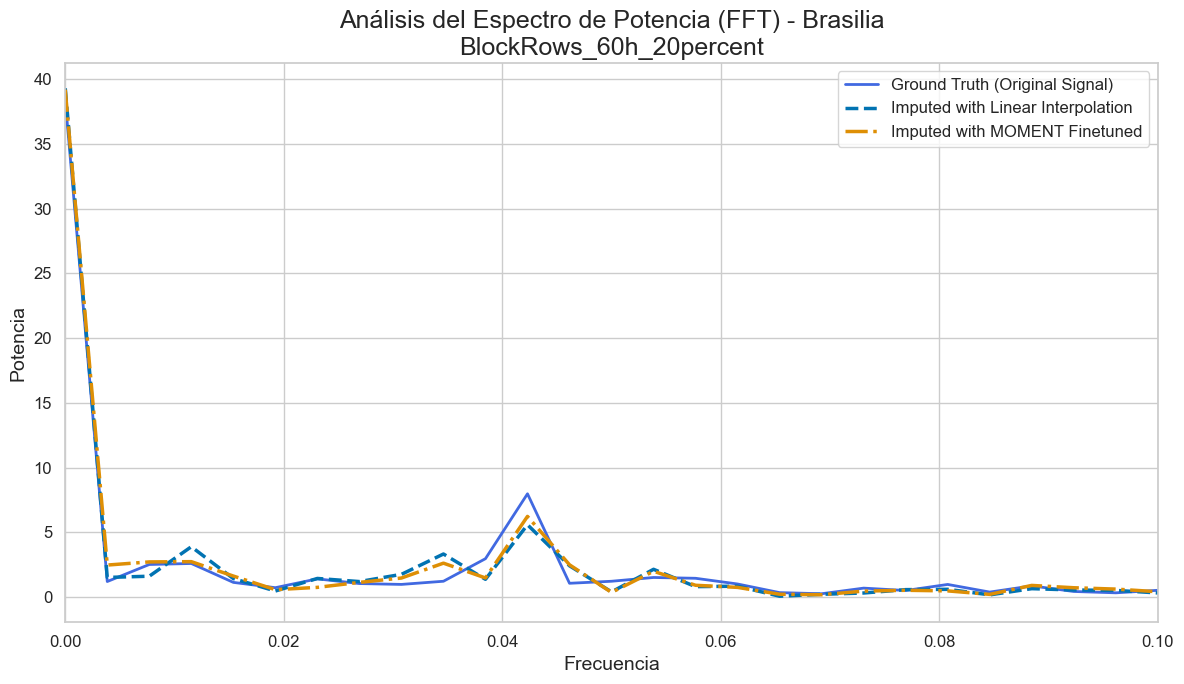

In [4]:
# =============================================================================
# CELDA 3: ANÁLISIS DE FRECUENCIA (FFT) PARA LA PARADOJA DEL PREPROCESADOR
# =============================================================================
print("--- Iniciando Análisis de Frecuencia (FFT) ---")

# --- Mapeo de nombres de carpeta a nombres legibles ---
# Ajusta los nombres de las carpetas si son diferentes
imputation_map = {
    'Linear Interpolation': 'Linear Interpolation',
    'MOMENT_FT_Optimized': 'MOMENT Finetuned'
}

# --- Cargar los datos necesarios ---
# 1. Ground Truth
series_gt = df_gt_city[TARGET_VARIABLE]

# 2. Archivo con NaNs para saber dónde estaba el hueco
nan_file_path = find_nan_file(CITY_FOR_ANALYSIS, SCENARIO_FOR_ANALYSIS, REP_FOR_ANALYSIS)
if nan_file_path:
    df_with_nans = pd.read_csv(nan_file_path)
    nan_mask = df_with_nans[TARGET_VARIABLE].isnull()
    # Encontrar el bloque de nulos más grande para visualizar
    nan_blocks = nan_mask.astype(int).diff().fillna(0)
    starts = nan_blocks[nan_blocks == 1].index
    ends = nan_blocks[nan_blocks == -1].index
    if not ends.empty and starts[0] > ends[0]:
        starts = starts.insert(0,0) # If it starts with NaNs
    if len(starts) > len(ends):
        ends = ends.append(pd.Index([len(nan_mask)]))

    block_lengths = ends.values - starts.values
    longest_block_idx = np.argmax(block_lengths)
    start_idx = starts[longest_block_idx] - 100 # Un poco de contexto antes
    end_idx = ends[longest_block_idx] + 100   # Un poco de contexto después
    start_idx = max(0, start_idx)
    end_idx = min(len(series_gt), end_idx)
    print(f"Analizando el segmento de índice {start_idx} a {end_idx}")
else:
    print("No se encontró el archivo con NaNs. Usando un segmento de ejemplo.")
    start_idx, end_idx = 1000, 1500

# --- Función para calcular el espectro de potencia ---
def get_power_spectrum(series):
    N = len(series)
    yf = fft.fft(series.values)
    xf = fft.fftfreq(N, 1)[:N//2] # Frecuencia (asumiendo 1 unidad de tiempo por muestra)
    power = 2.0/N * np.abs(yf[0:N//2])
    return xf, power

# --- Generar y plotear los espectros ---
plt.figure(figsize=(12, 7))
ax = plt.gca()

# 1. Espectro del Ground Truth
xf_gt, power_gt = get_power_spectrum(series_gt[start_idx:end_idx])
ax.plot(xf_gt, power_gt, label='Ground Truth (Original Signal)', color='royalblue', linewidth=2)

# 2. Espectro de los datos imputados
for folder_name, plot_label in imputation_map.items():
    file_path = find_imputed_file(folder_name, CITY_FOR_ANALYSIS, SCENARIO_FOR_ANALYSIS, REP_FOR_ANALYSIS)
    if file_path:
        df_imputed = pd.read_csv(file_path)
        series_imputed = df_imputed[TARGET_VARIABLE]
        xf_imputed, power_imputed = get_power_spectrum(series_imputed[start_idx:end_idx])
        linestyle = '--' if 'Linear' in plot_label else '-.'
        ax.plot(xf_imputed, power_imputed, label=f'Imputed with {plot_label}', linestyle=linestyle, linewidth=2.5)

ax.set_title(f'Análisis del Espectro de Potencia (FFT) - {CITY_FOR_ANALYSIS}\n{SCENARIO_FOR_ANALYSIS}')
ax.set_xlabel('Frecuencia')
ax.set_ylabel('Potencia')
ax.set_xlim(0, 0.1) # Enfocarse en las frecuencias más bajas e interesantes
ax.legend()
ax.grid(True)
plt.tight_layout()

# Guardar la figura
fft_plot_path = os.path.join(ANALYSIS_OUTPUT_DIR, 'fft_analysis.png')
plt.savefig(fft_plot_path, dpi=300)
print(f"Gráfico de FFT guardado en: {fft_plot_path}")
plt.show()

--- Iniciando Análisis de Importancia de Características ---
Entrenando RF Forecaster con datos de 'Linear Interpolation'...
Entrenando RF Forecaster con datos de 'MOMENT Finetuned'...
Gráfico de importancia de características guardado en: c:\Users\fdemiguel\Documentos\TFM_Ambiental\AIR QUALITY\analisis_avanzado\feature_importance.png


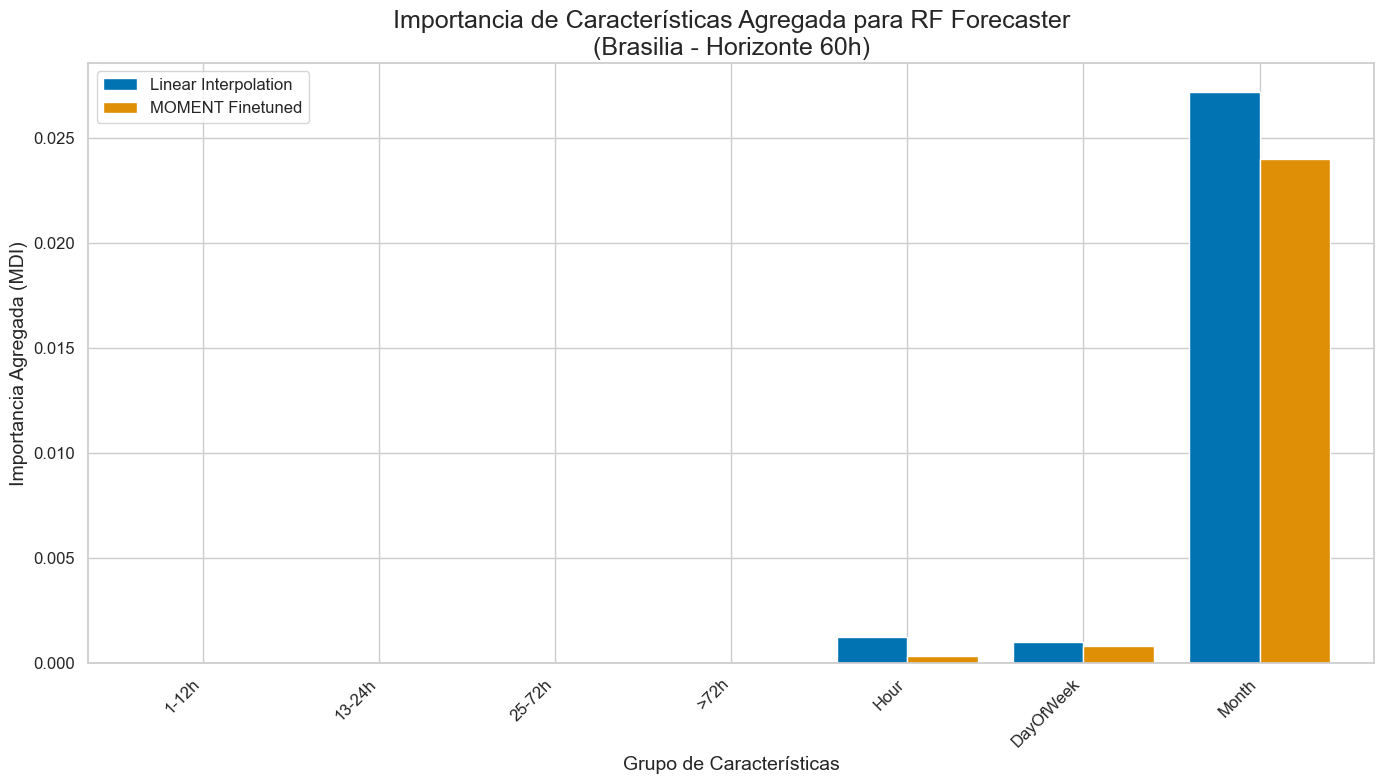

In [5]:
# =============================================================================
# CELDA 4: ANÁLISIS DE IMPORTANCIA DE CARACTERÍSTICAS (FEATURE IMPORTANCE)
# =============================================================================
print("--- Iniciando Análisis de Importancia de Características ---")

# --- Recrear la función de generación de features de tu notebook de predicción ---
def create_multivariate_lagged_features_rf(df, target_col, exo_cols, time_cols, n_lags_target, n_lags_exo, horizon):
    features = []
    # Usamos los mismos lags que en tu script original
    lags_target = list(range(horizon, n_lags_target + horizon))
    lags_exo = list(range(horizon, n_lags_exo + horizon))
    
    for i in lags_target:
        features.append(df[target_col].shift(i).rename(f'{target_col}_lag{i}'))
    for exo_col in exo_cols:
        if exo_col != target_col:
            for i in lags_exo:
                features.append(df[exo_col].shift(i).rename(f'{exo_col}_lag{i}'))
    for tf_col in time_cols:
        if tf_col in df.columns:
            features.append(df[tf_col])
    return pd.concat(features, axis=1)

# --- Parámetros del RF Forecaster (de tu notebook de predicción) ---
N_LAGS_AQI = 120
N_LAGS_EXO = 120
PREDICTION_HORIZON_FOR_ANALYSIS = 60 # Analizamos para el horizonte más lejano
EXOGENOUS_COLS = ['CO', 'NO2', 'SO2', 'O3', 'PM2.5', 'PM10']
TIME_FEATURES = ['Hour', 'DayOfWeek', 'Month']

# --- Mapeo de nombres de carpeta a nombres legibles (ajusta si es necesario) ---
imputation_map = {
    'Linear Interpolation': 'Linear Interpolation',
    'MOMENT_FT_Optimized': 'MOMENT Finetuned'
}

# --- Entrenar modelos y obtener importancias ---
importances = {}
for folder_name, plot_label in imputation_map.items():
    print(f"Entrenando RF Forecaster con datos de '{plot_label}'...")
    file_path = find_imputed_file(folder_name, CITY_FOR_ANALYSIS, SCENARIO_FOR_ANALYSIS, REP_FOR_ANALYSIS)
    if not file_path:
        print(f"  Archivo no encontrado para {plot_label}, saltando.")
        continue
        
    df_imputed = pd.read_csv(file_path)
    # Asegurarse de que las columnas de tiempo existen
    df_imputed['Date'] = pd.to_datetime(df_imputed['Date'])
    df_imputed['Hour'] = df_imputed['Date'].dt.hour
    df_imputed['DayOfWeek'] = df_imputed['Date'].dt.dayofweek
    df_imputed['Month'] = df_imputed['Date'].dt.month
    
    X = create_multivariate_lagged_features_rf(df_imputed, TARGET_VARIABLE, EXOGENOUS_COLS, TIME_FEATURES, N_LAGS_AQI, N_LAGS_EXO, PREDICTION_HORIZON_FOR_ANALYSIS)
    y = df_gt_city[TARGET_VARIABLE]

    full_data = pd.concat([X, y], axis=1).dropna()
    X_train, y_train = full_data.drop(columns=[TARGET_VARIABLE]), full_data[TARGET_VARIABLE]

    # Usamos un modelo un poco más rápido para este análisis interactivo
    model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    model.fit(X_train, y_train)
    
    importances[plot_label] = pd.Series(model.feature_importances_, index=X_train.columns)

# --- Visualizar las importancias ---
if importances:
    df_importances = pd.DataFrame(importances)
    
    # Agrupar lags para mejor visualización
    lag_cols = [c for c in df_importances.index if 'lag' in c]
    time_cols = [c for c in df_importances.index if c in TIME_FEATURES]
    
    df_lag_imp = df_importances.loc[lag_cols]
    df_time_imp = df_importances.loc[time_cols]
    
    # --- *** CORRECCIÓN APLICADA AQUÍ *** ---
    # Extraer el número del lag como una serie numérica
    lag_numbers = df_lag_imp.index.str.extract(r'_lag(\d+)').astype(int).iloc[:, 0]
    
    # Usar pd.cut para crear los grupos de forma vectorizada
    bins = [0, 12, 24, 72, np.inf]
    labels = ['1-12h', '13-24h', '25-72h', '>72h']
    df_lag_imp['lag_group'] = pd.cut(lag_numbers, bins=bins, labels=labels, right=True)
    # --- *** FIN DE LA CORRECCIÓN *** ---

    df_lag_summary = df_lag_imp.groupby('lag_group').sum()
    
    df_summary = pd.concat([df_lag_summary, df_time_imp])
    
    df_summary.plot(kind='bar', figsize=(14, 8), width=0.8)
    plt.title(f'Importancia de Características Agregada para RF Forecaster\n({CITY_FOR_ANALYSIS} - Horizonte {PREDICTION_HORIZON_FOR_ANALYSIS}h)')
    plt.ylabel('Importancia Agregada (MDI)')
    plt.xlabel('Grupo de Características')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    
    fi_plot_path = os.path.join(ANALYSIS_OUTPUT_DIR, 'feature_importance.png')
    plt.savefig(fi_plot_path, dpi=300)
    print(f"Gráfico de importancia de características guardado en: {fi_plot_path}")
    plt.show()
else:
    print("No se pudieron generar los datos de importancia de características.")

In [6]:
# =============================================================================
# CELDA 5: TEST DE SIGNIFICANCIA ESTADÍSTICA (WILCOXON) - CORREGIDA
# =============================================================================
print("--- Iniciando Tests de Significancia ---")

# --- Cargar los resultados de predicción de TODOS los modelos ---
# Usaremos los resultados del RandomForest Forecaster como ejemplo
prediction_method_folder = 'RandomForest_full_FT' 
metrics_file = os.path.join(PREDICTIONS_BASE_DIR, prediction_method_folder, 'metricas', f'ALL_prediction_metrics_detailed_{prediction_method_folder}.csv')

try:
    df_preds = pd.read_csv(metrics_file)
    print(f"Métricas de predicción cargadas desde {metrics_file}")
except FileNotFoundError:
    print(f"ERROR: No se encontró el archivo de métricas {metrics_file}. No se pueden ejecutar los tests.")
    df_preds = pd.DataFrame()

if not df_preds.empty:
    # --- *** CORRECCIÓN APLICADA AQUÍ *** ---
    # La clave es agrupar por las condiciones experimentales (Ciudad, Escenario, Horizonte)
    # y usar el MAE de cada método de imputación como columnas.
    # Usamos aggfunc='mean' por si en el futuro incluyes más repeticiones. 
    # Con tus datos actuales, como solo hay una repetición, simplemente tomará ese valor.
    df_pivot = df_preds.pivot_table(
        index=['City', 'Scenario', 'Horizon_h'], # Usamos estas como las "pruebas" pareadas
        columns='Imputation_Method',
        values='MAE',
        aggfunc='mean' # Agregamos por si hay múltiples repeticiones (aunque ahora solo hay una)
    ).dropna()
    
    # Renombrar métodos para que quepan mejor en las tablas
    rename_map = {
        'Linear Interpolation': 'Linear',
        'LSTM-VAE': 'LSTM-VAE',
        'MOMENT Finetuned': 'MOMENT-FT',
        'MOMENT Pretrained': 'MOMENT-Pre',
        'Random Forest': 'RF Imputer',
        'SARIMA': 'SARIMA'
    }
    df_pivot = df_pivot.rename(columns=rename_map)
    
    print("\nVista de la tabla pivotada para el test:")
    print(df_pivot.head())

    imputation_methods = df_pivot.columns
    
    # --- Comparar 'Linear' contra los demás ---
    base_method = 'Linear'
    if base_method not in imputation_methods:
        print(f"ERROR: El método base '{base_method}' no está en los resultados.")
    else:
        results = []
        for method_to_compare in imputation_methods:
            if method_to_compare == base_method:
                continue
            
            # Wilcoxon signed-rank test
            # H0: la mediana de las diferencias entre pares es cero (no hay diferencia)
            # H1: la mediana de las diferencias no es cero (hay diferencia)
            try:
                stat, p_value = wilcoxon(df_pivot[base_method], df_pivot[method_to_compare])
                
                # Interpretación
                if p_value < 0.05:
                    significance = 'Yes'
                    # Comprobar qué método es mejor
                    if df_pivot[base_method].mean() < df_pivot[method_to_compare].mean():
                        conclusion = f"'{base_method}' es significativamente mejor."
                    else:
                        conclusion = f"'{method_to_compare}' es significativamente mejor."
                else:
                    significance = 'No'
                    conclusion = "No hay diferencia significativa."

                results.append({
                    'Comparison': f'{base_method} vs {method_to_compare}',
                    'Statistic': stat,
                    'p_value': f"{p_value:.4f}",
                    'Significant (p < 0.05)': significance,
                    'Conclusion': conclusion
                })
            except ValueError as e:
                # Esto puede pasar si las dos series son idénticas
                results.append({
                    'Comparison': f'{base_method} vs {method_to_compare}',
                    'Statistic': 'N/A',
                    'p_value': 'N/A',
                    'Significant (p < 0.05)': 'N/A',
                    'Conclusion': f"Error en el test: {e}"
                })
            
        df_wilcoxon = pd.DataFrame(results)
        print("\nResultados del Test de Wilcoxon (Comparando MAE de pipelines con RF Forecaster):")
        print(df_wilcoxon.to_string())
        
        # Guardar resultados
        wilcoxon_path = os.path.join(ANALYSIS_OUTPUT_DIR, 'wilcoxon_test_results.csv')
        df_wilcoxon.to_csv(wilcoxon_path, index=False)
        print(f"\nResultados del test guardados en: {wilcoxon_path}")

--- Iniciando Tests de Significancia ---
Métricas de predicción cargadas desde c:\Users\fdemiguel\Documentos\TFM_Ambiental\AIR QUALITY\predicciones\RandomForest_full_FT\metricas\ALL_prediction_metrics_detailed_RandomForest_full_FT.csv

Vista de la tabla pivotada para el test:
Imputation_Method                           LSTM-VAE    Linear  MOMENT-FT  \
City     Scenario                Horizon_h                                  
Brasilia BlockRows_12h_20percent 12         1.151025  1.061690   1.099441   
                                 24         1.288743  1.186419   1.229607   
                                 36         1.392084  1.269906   1.335695   
                                 48         1.451707  1.332327   1.389808   
                                 60         1.499350  1.367201   1.446026   

Imputation_Method                           MOMENT-Pre  RF Imputer    SARIMA  
City     Scenario                Horizon_h                                    
Brasilia BlockRows_12h_20

In [13]:
# =============================================================================
# CELDA 6: PROPAGACIÓN DE INCERTIDUMBRE (MONTE CARLO) - CORRECCIÓN ZONA HORARIA
# =============================================================================
print("--- Defining functions for Uncertainty Propagation (Timezone-Aware) ---")

# --- PARÁMETROS PARA UQ ---
N_MONTE_CARLO_SAMPLES = 50
N_IMPUTER_MODELS = 10
N_LAGS = list(range(1, 13)) + [24, 48, 72]

# --- *** FUNCIONES AUXILIARES CORREGIDAS Y MEJORADAS *** ---
def find_imputed_file_robust(imputation_method_folder, city, scenario, rep=1):
    city_safe = city.replace(" ", "_")
    possible_subfolders = ['CSVs', 'CSVs_unified']
    for subfolder in possible_subfolders:
        base_path = os.path.join(IMPUTATIONS_BASE_DIR, imputation_method_folder, subfolder, city_safe, scenario)
        if os.path.exists(base_path):
            files = glob.glob(os.path.join(base_path, f"*_rep{rep}_*.csv"))
            if files: return files[0]
    return None

def create_univariant_features(df, target_col, time_cols, lags):
    features = pd.DataFrame(index=df.index)
    for tf_col in time_cols:
        if tf_col in df.columns: features[tf_col] = df[tf_col]
    for lag in lags:
        features[f'{target_col}_lag{lag}'] = df[target_col].shift(lag)
    return features

# --- 1. FUNCIÓN DE IMPUTACIÓN PROBABILÍSTICA (CORREGIDA) ---
def generate_ensemble_rf_imputation_samples(df_with_nans, imputer_ensemble, n_samples):
    # --- *** CORRECCIÓN DE ZONA HORARIA AQUÍ *** ---
    if 'Date' in df_with_nans.columns:
        # La opción utc=True lee la zona horaria del string, la convierte a UTC y luego la elimina.
        df_with_nans['Date'] = pd.to_datetime(df_with_nans['Date'], utc=True)
    
    if not all(col in df_with_nans.columns for col in TIME_FEATURES):
        df_with_nans['Hour'] = df_with_nans['Date'].dt.hour
        df_with_nans['DayOfWeek'] = df_with_nans['Date'].dt.dayofweek
        df_with_nans['Month'] = df_with_nans['Date'].dt.month
    
    df_imputed_base = df_with_nans.copy().interpolate(method='linear').ffill().bfill()
    nan_indices_mask = df_with_nans[TARGET_VARIABLE].isnull()
    
    if not nan_indices_mask.any():
        return [df_with_nans.copy() for _ in range(n_samples)]
        
    X = create_univariant_features(df_imputed_base, TARGET_VARIABLE, TIME_FEATURES, N_LAGS)
    valid_indices = X.loc[nan_indices_mask].dropna().index
    X_to_impute_clean = X.loc[valid_indices]

    if X_to_impute_clean.empty:
        return [df_imputed_base.copy() for _ in range(n_samples)]
        
    model_predictions = np.array([model.predict(X_to_impute_clean) for model in imputer_ensemble])
    
    variance_of_model_preds = np.var(model_predictions[:, 0]) if model_predictions.shape[1] > 0 else 0
    print(f"DEBUG: Varianza de las predicciones de los modelos para el primer NaN: {variance_of_model_preds}")
    
    imputed_datasets = []
    for _ in tqdm(range(n_samples), desc="Generando muestras de imputación RF (Ensamblaje)", leave=False):
        model_indices = np.random.randint(0, len(imputer_ensemble), size=len(valid_indices))
        imputed_values = model_predictions[model_indices, np.arange(len(valid_indices))]
        
        df_sample = df_with_nans.copy()
        df_sample.loc[valid_indices, TARGET_VARIABLE] = imputed_values
        df_sample[TARGET_VARIABLE] = df_sample[TARGET_VARIABLE].interpolate(method='linear', limit_direction='both').ffill().bfill()
        imputed_datasets.append(df_sample)
        
    return imputed_datasets

# --- 2. Función para propagar la incertidumbre (sin cambios) ---
def propagate_uncertainty_to_forecasts_calibrated(imputed_datasets, forecaster_model, horizon):
    all_forecasts = []
    for df_imputed in tqdm(imputed_datasets, desc="Propagando incertidumbre (calibrated model)", leave=False):
        X_full = create_multivariate_lagged_features_rf(df_imputed, TARGET_VARIABLE, EXOGENOUS_COLS, TIME_FEATURES, N_LAGS_AQI_CALIBRATED, N_LAGS_EXO_CALIBRATED, horizon)
        predictable_indices = X_full.dropna().index
        if len(predictable_indices) == 0: continue
        X_predict = X_full.loc[predictable_indices]
        predictions = forecaster_model.predict(X_predict)
        all_forecasts.append(pd.Series(predictions, index=predictable_indices))
    if not all_forecasts: return pd.DataFrame()
    return pd.concat(all_forecasts, axis=1)

print("Funciones para UQ (Timezone-Aware) definidas.")

--- Defining functions for Uncertainty Propagation (Timezone-Aware) ---
Funciones para UQ (Timezone-Aware) definidas.


--- Executing UQ pipeline with a Slightly Weaker Forecaster for more Variance ---
Training an ensemble of 10 RF Imputers for Brasilia...
Imputer ensemble trained.
Training a CALIBRATED RF Forecaster for Brasilia...
DEBUG: Varianza de las predicciones de los modelos para el primer NaN: 0.02246359233933424


Generando muestras de imputación RF (Ensamblaje):   0%|          | 0/50 [00:00<?, ?it/s]

Propagating uncertainty (calibrated model):   0%|          | 0/50 [00:00<?, ?it/s]

Calibrated probabilistic forecast plot (v2) saved to: c:\Users\fdemiguel\Documentos\TFM_Ambiental\AIR QUALITY\analisis_avanzado\probabilistic_forecast_calibrated_v2_en.png


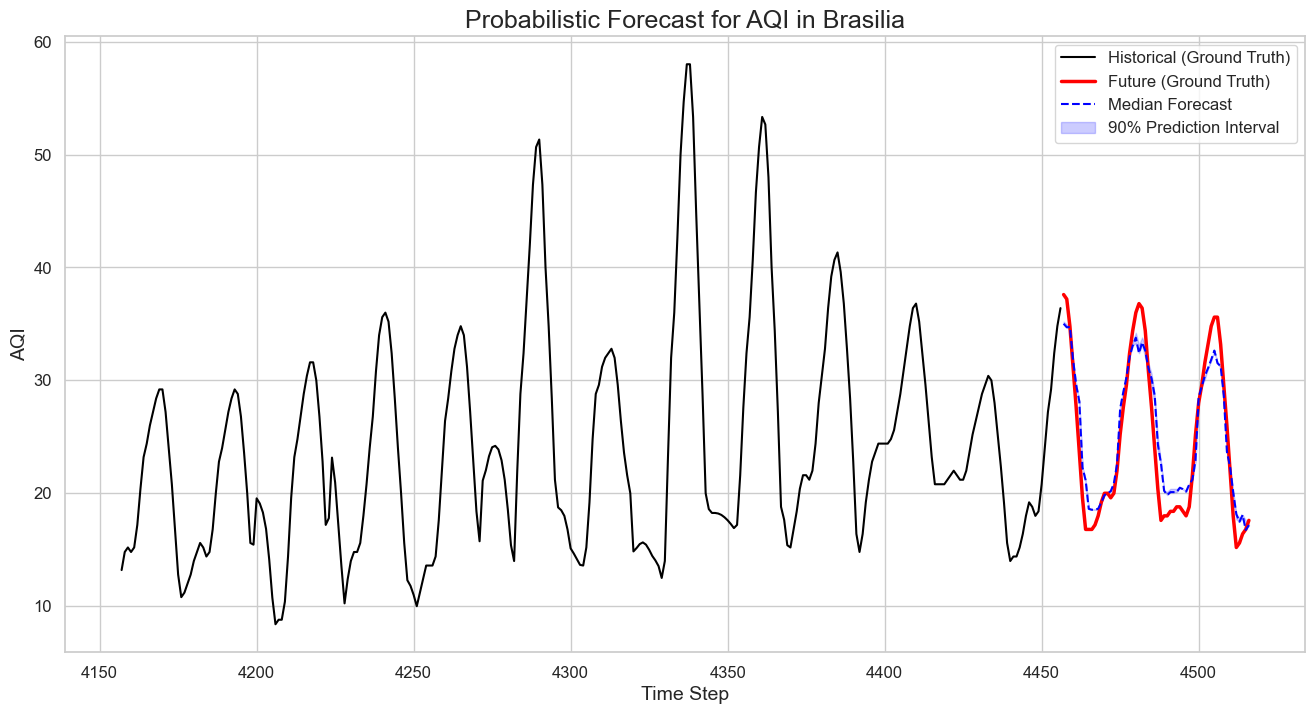

In [8]:
# =============================================================================
# CELDA 7: EJECUCIÓN DEL ANÁLISIS DE INCERTIDUMBRE (FORECASTER LIGERAMENTE MÁS VARIABLE)
# =============================================================================
print("--- Executing UQ pipeline with a Slightly Weaker Forecaster for more Variance ---")

# --- 1. Prepare data and models ---
df_gt_city['Date'] = pd.to_datetime(df_gt_city['Date'])
df_gt_city['Hour'], df_gt_city['DayOfWeek'], df_gt_city['Month'] = df_gt_city['Date'].dt.hour, df_gt_city['Date'].dt.dayofweek, df_gt_city['Date'].dt.month

# --- A. Entrenar un ENSAMBLAJE de RF Imputers MÁS DIVERSO ---
print(f"Training an ensemble of {N_IMPUTER_MODELS} RF Imputers for {CITY_FOR_ANALYSIS}...")
X_imp_train_full = create_univariant_features(df_gt_city, TARGET_VARIABLE, TIME_FEATURES, N_LAGS)
y_imp_train_full = df_gt_city[TARGET_VARIABLE]
train_data_imp = pd.concat([X_imp_train_full, y_imp_train_full], axis=1).dropna()
X_train, y_train = train_data_imp.drop(columns=[TARGET_VARIABLE]), train_data_imp[TARGET_VARIABLE]

imputer_ensemble = []
for i in range(N_IMPUTER_MODELS):
    model = RandomForestRegressor(n_estimators=50, n_jobs=-1, random_state=i, max_features=0.5, max_depth=10) 
    model.fit(X_train, y_train)
    imputer_ensemble.append(model)
print("Imputer ensemble trained.")

# --- B. Entrenar un RF Forecaster CALIBRADO ---
print(f"Training a CALIBRATED RF Forecaster for {CITY_FOR_ANALYSIS}...")
imputation_folder_linear = 'Linear Interpolation' 
imputed_linear_path = find_imputed_file(imputation_folder_linear, CITY_FOR_ANALYSIS, SCENARIO_FOR_ANALYSIS, REP_FOR_ANALYSIS)
if imputed_linear_path is None: raise FileNotFoundError(f"Linear imputation file not found in folder '{imputation_folder_linear}'.")

df_linear = pd.read_csv(imputed_linear_path)
df_linear['Date'] = pd.to_datetime(df_linear['Date'])
df_linear['Hour'], df_linear['DayOfWeek'], df_linear['Month'] = df_linear['Date'].dt.hour, df_linear['Date'].dt.dayofweek, df_linear['Date'].dt.month

N_LAGS_AQI_CALIBRATED = 72
N_LAGS_EXO_CALIBRATED = 72
X_fore_train_full = create_multivariate_lagged_features_rf(df_linear, TARGET_VARIABLE, EXOGENOUS_COLS, TIME_FEATURES, N_LAGS_AQI_CALIBRATED, N_LAGS_EXO_CALIBRATED, PREDICTION_HORIZON_FOR_ANALYSIS)
y_fore_train_full = df_gt_city[TARGET_VARIABLE]
train_data_fore = pd.concat([X_fore_train_full, y_fore_train_full], axis=1).dropna()

# --- *** CAMBIO AQUÍ: Forecaster ligeramente más débil para aumentar la varianza de salida *** ---
rf_forecaster = RandomForestRegressor(
    n_estimators=30,          # Menos árboles que antes (50 -> 30)
    random_state=42, 
    n_jobs=-1,
    max_depth=10,             # Un poco menos profundo (12 -> 10)
    min_samples_leaf=15,      # Ligeramente más general (10 -> 15)
    max_features=0.75         
)
rf_forecaster.fit(train_data_fore.drop(columns=[TARGET_VARIABLE]), train_data_fore[TARGET_VARIABLE])

# --- 2. Generar muestras de imputación (sin cambios) ---
df_with_nans = pd.read_csv(find_nan_file(CITY_FOR_ANALYSIS, SCENARIO_FOR_ANALYSIS, REP_FOR_ANALYSIS))
for col in EXOGENOUS_COLS:
    if col in df_with_nans.columns:
        df_with_nans[col] = df_with_nans[col].interpolate(method='linear').ffill().bfill()
imputed_samples = generate_ensemble_rf_imputation_samples(df_with_nans, imputer_ensemble, N_MONTE_CARLO_SAMPLES)

# --- 3. Propagar al forecast (sin cambios) ---
def propagate_uncertainty_to_forecasts_calibrated(imputed_datasets, forecaster_model, horizon):
    all_forecasts = []
    for df_imputed in tqdm(imputed_datasets, desc="Propagating uncertainty (calibrated model)", leave=False):
        X_full = create_multivariate_lagged_features_rf(df_imputed, TARGET_VARIABLE, EXOGENOUS_COLS, TIME_FEATURES, N_LAGS_AQI_CALIBRATED, N_LAGS_EXO_CALIBRATED, horizon)
        predictable_indices = X_full.dropna().index
        if len(predictable_indices) == 0: continue
        X_predict = X_full.loc[predictable_indices]
        predictions = forecaster_model.predict(X_predict)
        all_forecasts.append(pd.Series(predictions, index=predictable_indices))
    if not all_forecasts: return pd.DataFrame()
    return pd.concat(all_forecasts, axis=1)

probabilistic_forecasts = propagate_uncertainty_to_forecasts_calibrated(imputed_samples, rf_forecaster, PREDICTION_HORIZON_FOR_ANALYSIS)

# --- 4. Visualizar un ejemplo (sin cambios, solo nombre de archivo) ---
if not probabilistic_forecasts.empty:
    plot_start_index = probabilistic_forecasts.index[len(probabilistic_forecasts) // 2]
    plot_end_index = plot_start_index + PREDICTION_HORIZON_FOR_ANALYSIS
    forecast_slice = probabilistic_forecasts.loc[plot_start_index:plot_end_index-1]
    if not forecast_slice.empty:
        median = forecast_slice.median(axis=1)
        p05 = forecast_slice.quantile(0.01, axis=1)
        p95 = forecast_slice.quantile(0.99, axis=1)
        
        plt.figure(figsize=(16, 8))
        history_start = plot_start_index - HISTORY_LEN_FOR_PLOT
        plt.plot(df_gt_city.loc[history_start:plot_start_index-1, TARGET_VARIABLE], label='Historical (Ground Truth)', color='black')
        plt.plot(df_gt_city.loc[plot_start_index:plot_end_index-1, TARGET_VARIABLE], label='Future (Ground Truth)', color='red', linewidth=2.5, zorder=3)
        plt.plot(median, label='Median Forecast', color='blue', linestyle='--', zorder=4)
        plt.fill_between(median.index, p05, p95, color='blue', alpha=0.2, label='90% Prediction Interval', zorder=2)
        plt.title(f'Probabilistic Forecast for {TARGET_VARIABLE} in {CITY_FOR_ANALYSIS}')
        plt.xlabel('Time Step')
        plt.ylabel(TARGET_VARIABLE)
        plt.legend()
        plt.grid(True)
        
        uq_plot_path = os.path.join(ANALYSIS_OUTPUT_DIR, 'probabilistic_forecast_calibrated_v2_en.png')
        plt.savefig(uq_plot_path, dpi=300)
        print(f"Calibrated probabilistic forecast plot (v2) saved to: {uq_plot_path}")
        plt.show()
else:
    print("No probabilistic forecasts were generated to visualize.")

In [9]:
# =============================================================================
# CELDA 8: MÉTRICAS DE INCERTIDUMBRE (WINKLER & CRPS)
# =============================================================================

def winkler_score(y_true, lower_bound, upper_bound, alpha=0.1):
    """Calcula el Winkler Score."""
    score = np.where(
        y_true < lower_bound, (upper_bound - lower_bound) + (2 / alpha) * (lower_bound - y_true),
        np.where(
            y_true > upper_bound, (upper_bound - lower_bound) + (2 / alpha) * (y_true - upper_bound),
            (upper_bound - lower_bound)
        )
    )
    return np.mean(score)

def crps(y_true, samples):
    """Calcula el Continuous Ranked Probability Score."""
    n_samples = samples.shape[1]
    y_true_tiled = np.tile(y_true, (n_samples, 1)).T
    
    term1 = np.mean(np.abs(samples - y_true_tiled), axis=1)
    
    sum_abs_diff = 0
    for i in range(n_samples):
        for j in range(n_samples):
            sum_abs_diff += np.abs(samples[:, i] - samples[:, j])
    
    term2 = sum_abs_diff / (2 * n_samples**2)
    
    return np.mean(term1 - term2)


# --- Calcular métricas para el forecast generado ---
if 'forecast_slice' in locals() and not forecast_slice.empty:
    y_true_eval = df_gt_city.loc[forecast_slice.index, TARGET_VARIABLE].values
    samples_eval = forecast_slice.values
    
    # Asegurarse de que y_true_eval sea 1D
    if y_true_eval.ndim > 1:
        y_true_eval = y_true_eval.flatten()

    w_score = winkler_score(y_true_eval, p05.values, p95.values, alpha=0.1)
    c_score = crps(y_true_eval, samples_eval)

    print("\n--- Métricas de Evaluación Probabilística ---")
    print(f"Winkler Score (alpha=0.1): {w_score:.4f} (menor es mejor)")
    print(f"CRPS:                       {c_score:.4f} (menor es mejor)")


--- Métricas de Evaluación Probabilística ---
Winkler Score (alpha=0.1): 34.3510 (menor es mejor)
CRPS:                       1.7764 (menor es mejor)


--- Generating Comparative Forecast & Feature Importance Plots (Smart Split Point) ---
Optimal split point (containing full NaN block) found at index: 4423
Processing: Ground Truth...
Processing: Linear Interpolation...
Processing: MOMENT-FT...

Simplified feature importance comparison plot saved to: c:\Users\fdemiguel\Documentos\TFM_Ambiental\AIR QUALITY\analisis_avanzado\feature_importance_comparison_simplified.png


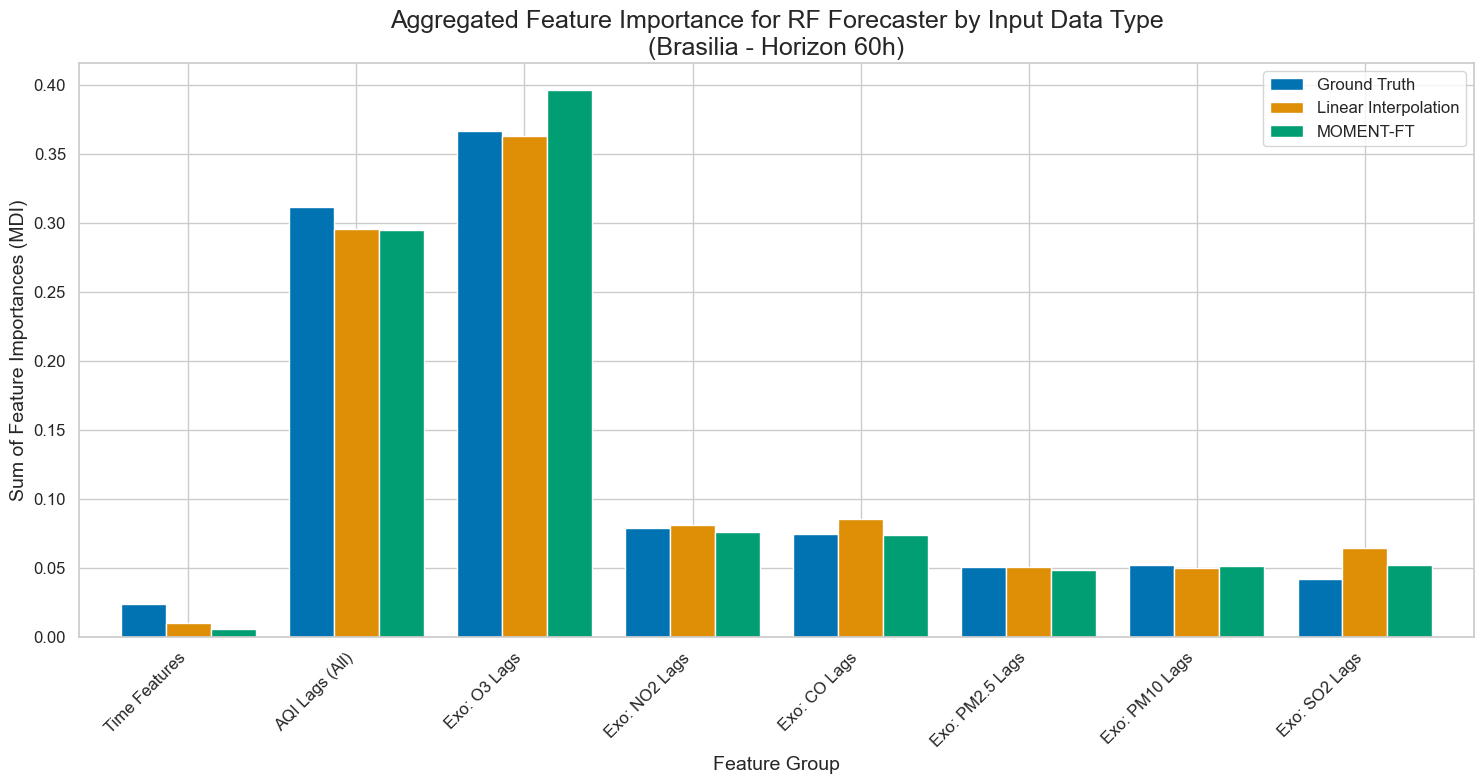


3-panel comparative forecast plot saved to: c:\Users\fdemiguel\Documentos\TFM_Ambiental\AIR QUALITY\analisis_avanzado\forecast_comparison_3panel_adjusted_history.png


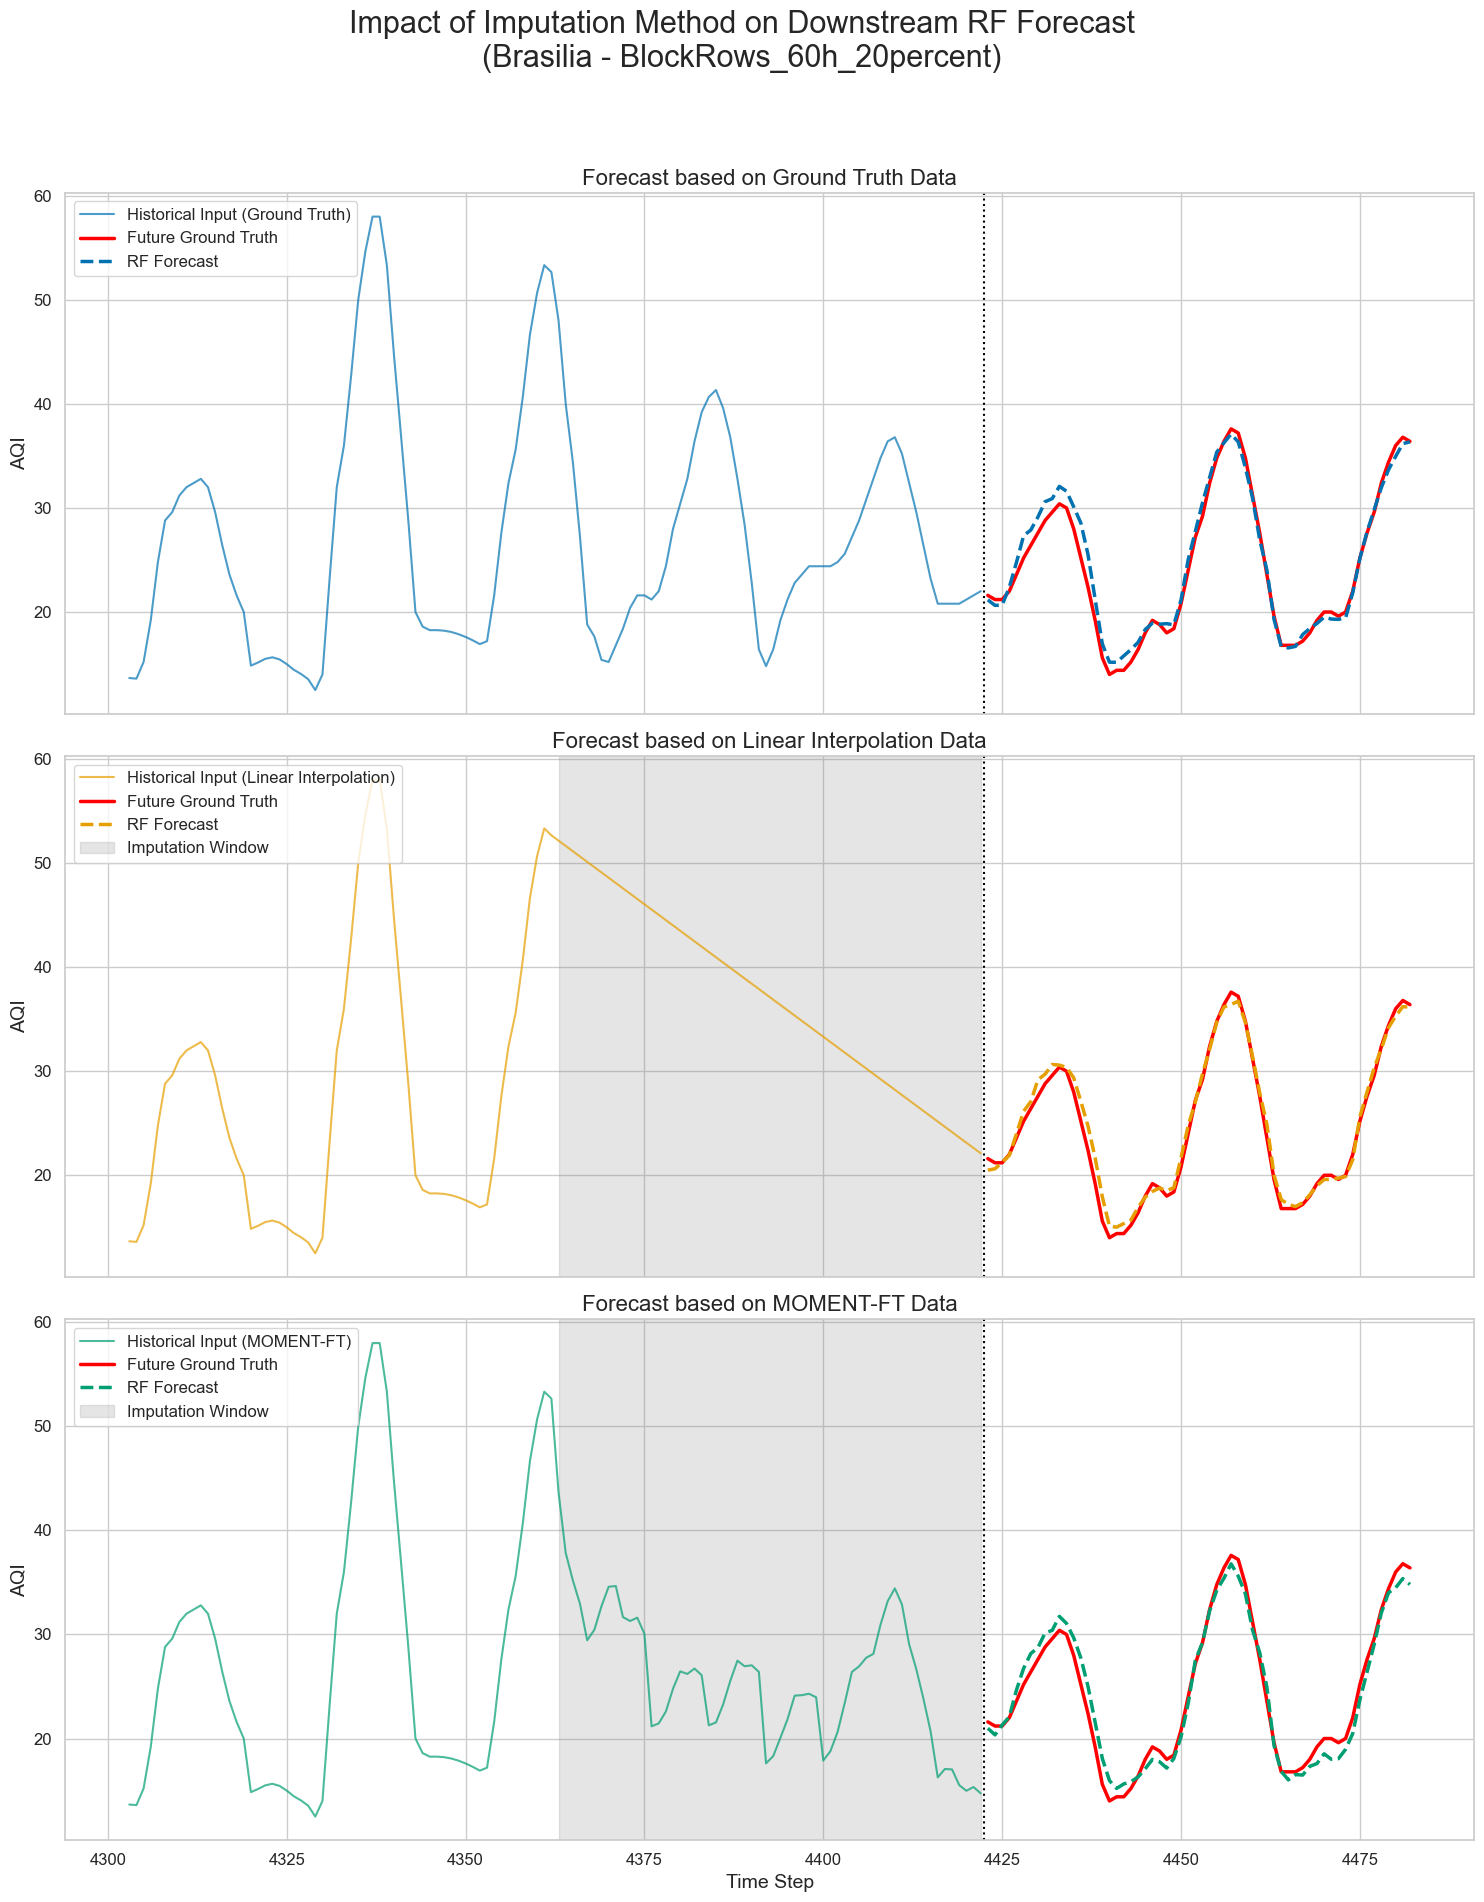

In [10]:
# =============================================================================
# CELDA 9: VISUALIZACIÓN COMPARATIVA (CON SELECCIÓN INTELIGENTE DE SPLIT POINT)
# =============================================================================
print("--- Generating Comparative Forecast & Feature Importance Plots (Smart Split Point) ---")

# --- 1. Cargar los datos necesarios (sin cambios) ---
imputation_map_comp = {
    'Original (Ground Truth)': 'Ground Truth',
    'Linear Interpolation': 'Linear Interpolation',
    'MOMENT_FT_Optimized': 'MOMENT-FT'
}

imputed_dfs = {}
imputed_dfs['Ground Truth'] = df_gt_city.copy()

linear_path = find_imputed_file('Linear Interpolation', CITY_FOR_ANALYSIS, SCENARIO_FOR_ANALYSIS, REP_FOR_ANALYSIS)
if linear_path:
    df_linear = pd.read_csv(linear_path)
    df_linear['Date'] = pd.to_datetime(df_linear['Date'])
    df_linear['Hour'], df_linear['DayOfWeek'], df_linear['Month'] = df_linear['Date'].dt.hour, df_linear['Date'].dt.dayofweek, df_linear['Date'].dt.month
    imputed_dfs['Linear Interpolation'] = df_linear
else:
    print("Warning: Could not find file for 'Linear Interpolation'")

moment_path = find_imputed_file('MOMENT_FT_Optimized', CITY_FOR_ANALYSIS, SCENARIO_FOR_ANALYSIS, REP_FOR_ANALYSIS)
if moment_path:
    df_moment = pd.read_csv(moment_path)
    df_moment['Date'] = pd.to_datetime(df_moment['Date'])
    df_moment['Hour'], df_moment['DayOfWeek'], df_moment['Month'] = df_moment['Date'].dt.hour, df_moment['Date'].dt.dayofweek, df_moment['Date'].dt.month
    imputed_dfs['MOMENT-FT'] = df_moment
else:
    print("Warning: Could not find file for 'MOMENT-FT'")

nan_file_path = find_nan_file(CITY_FOR_ANALYSIS, SCENARIO_FOR_ANALYSIS, REP_FOR_ANALYSIS)
if not nan_file_path: raise FileNotFoundError("NaN file not found.")
df_with_nans = pd.read_csv(nan_file_path)
original_nan_indices = set(df_with_nans[df_with_nans[TARGET_VARIABLE].isnull()].index)

# --- 2. Encontrar el punto de visualización ideal (LÓGICA MEJORADA) ---
N_LAGS_AQI_COMP = 120
N_LAGS_EXO_COMP = 120
HORIZON_COMP = 60
max_lags = max(N_LAGS_AQI_COMP, N_LAGS_EXO_COMP)

# Primero, encontrar todos los bloques de NaNs
nan_mask = df_with_nans[TARGET_VARIABLE].isnull()
nan_blocks_series = nan_mask.astype(int).diff().fillna(0)
starts = nan_blocks_series[nan_blocks_series == 1].index
ends = nan_blocks_series[nan_blocks_series == -1].index
if not starts.empty and (ends.empty or starts[0] > ends[0]):
    starts = starts.insert(0, nan_mask[nan_mask].index[0])
if len(starts) > len(ends):
    ends = ends.append(pd.Index([nan_mask[nan_mask].index[-1] + 1]))
nan_blocks = list(zip(starts, ends))

# Buscar un split_point que contenga un bloque completo de NaNs en su historial
ideal_split_points = []
for start_nan, end_nan in nan_blocks:
    # El punto ideal para empezar la predicción es justo después del bloque de NaNs
    candidate_sp = end_nan
    
    # Verificar si este punto es válido
    history_start = candidate_sp - max_lags
    future_end = candidate_sp + HORIZON_COMP
    
    # Condiciones:
    # 1. Hay suficiente historial antes del inicio de la ventana de lags
    # 2. Hay suficientes datos en el futuro para toda la predicción
    # 3. No hay (otros) NaNs en el horizonte de predicción
    if history_start >= 0 and future_end <= len(df_gt_city):
        future_indices = set(range(candidate_sp, future_end))
        if not future_indices.intersection(original_nan_indices):
            ideal_split_points.append(candidate_sp)

if ideal_split_points:
    split_point = random.choice(ideal_split_points)
    print(f"Optimal split point (containing full NaN block) found at index: {split_point}")
else:
    # Si no se encuentra un punto ideal, usar la lógica de respaldo anterior
    print("Could not find a perfect split point containing a full NaN block. Using fallback logic.")
    possible_starts = range(max_lags + HORIZON_COMP, len(df_gt_city) - HORIZON_COMP)
    valid_split_points = []
    for p in possible_starts:
        history_indices = set(range(p - max_lags, p))
        future_indices = set(range(p, p + HORIZON_COMP))
        if history_indices.intersection(original_nan_indices) and not future_indices.intersection(original_nan_indices):
            valid_split_points.append(p)
    if not valid_split_points: raise ValueError("Could not find any suitable split point for visualization.")
    split_point = random.choice(valid_split_points)
    print(f"Fallback split point found at index: {split_point}")


# --- 3. Bucle para entrenar y obtener resultados (sin cambios) ---
plot_inputs = [('Ground Truth', '#0072B2'), ('Linear Interpolation', '#E69F00'), ('MOMENT-FT', '#009E73')]
all_feature_importances = {}
all_predictions = {}
trained_forecasters = {}
for input_label, color in plot_inputs:
    print(f"Processing: {input_label}...")
    df_input = imputed_dfs.get(input_label)
    if df_input is None: continue
    X_train_full = create_multivariate_lagged_features_rf(df_input, TARGET_VARIABLE, EXOGENOUS_COLS, TIME_FEATURES, N_LAGS_AQI_COMP, N_LAGS_EXO_COMP, HORIZON_COMP)
    y_train_full = df_gt_city[TARGET_VARIABLE]
    train_data_comp = pd.concat([X_train_full, y_train_full], axis=1).dropna()
    X_train_c, y_train_c = train_data_comp.drop(columns=[TARGET_VARIABLE]), train_data_comp[TARGET_VARIABLE]
    rf_forecaster = RandomForestRegressor(n_estimators=100, max_depth=15, min_samples_split=5, min_samples_leaf=2, max_features='sqrt', random_state=42, n_jobs=-1)
    rf_forecaster.fit(X_train_c, y_train_c)
    trained_forecasters[input_label] = rf_forecaster
    all_feature_importances[input_label] = pd.Series(rf_forecaster.feature_importances_, index=X_train_c.columns)
    X_predict_slice = X_train_full.loc[split_point : split_point + HORIZON_COMP - 1]
    all_predictions[input_label] = pd.Series(rf_forecaster.predict(X_predict_slice), index=X_predict_slice.index)

# --- 4. Crear el gráfico de Feature Importance (sin cambios) ---
df_importances_all = pd.DataFrame(all_feature_importances)
def get_feature_group_simplified(feature_name):
    if feature_name in TIME_FEATURES: return 'Time Features'
    if 'AQI_lag' in feature_name: return 'AQI Lags (All)'
    for exo in EXOGENOUS_COLS:
        if f'{exo}_lag' in feature_name: return f'Exo: {exo} Lags'
    return 'Other'
df_importances_all['group'] = df_importances_all.index.map(get_feature_group_simplified)
df_summary = df_importances_all.groupby('group').sum()
category_order = ['Time Features', 'AQI Lags (All)', 'Exo: O3 Lags', 'Exo: NO2 Lags', 'Exo: CO Lags', 'Exo: PM2.5 Lags', 'Exo: PM10 Lags', 'Exo: SO2 Lags']
df_summary = df_summary.reindex(category_order).dropna()
df_summary.plot(kind='bar', figsize=(15, 8), width=0.8)
plt.title(f'Aggregated Feature Importance for RF Forecaster by Input Data Type\n(Brasilia - Horizon {HORIZON_COMP}h)')
plt.ylabel('Sum of Feature Importances (MDI)')
plt.xlabel('Feature Group')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
fi_plot_path = os.path.join(ANALYSIS_OUTPUT_DIR, 'feature_importance_comparison_simplified.png')
plt.savefig(fi_plot_path, dpi=300)
print(f"\nSimplified feature importance comparison plot saved to: {fi_plot_path}")
plt.show()

# --- 5. Crear el panel de 3 gráficos de predicción (con historial ajustado) ---
fig, axes = plt.subplots(3, 1, figsize=(15, 20), sharex=True, sharey=True)
fig.suptitle(f'Impact of Imputation Method on Downstream RF Forecast\n({CITY_FOR_ANALYSIS} - {SCENARIO_FOR_ANALYSIS})', fontsize=22)
for ax, (input_label, color) in zip(axes, plot_inputs):
    df_input = imputed_dfs.get(input_label)
    prediction = all_predictions.get(input_label)
    if df_input is None or prediction is None: continue
    
    history_start = split_point - max_lags
    
    ax.plot(df_input.loc[history_start:split_point-1, TARGET_VARIABLE], label=f'Historical Input ({input_label})', color=color, alpha=0.7)
    ax.plot(df_gt_city.loc[split_point:split_point + HORIZON_COMP - 1, TARGET_VARIABLE], label='Future Ground Truth', color='red', linewidth=2.5, zorder=5)
    ax.plot(prediction, label=f'RF Forecast', color=color, linestyle='--', linewidth=2.5, zorder=6)
    
    history_nan_indices = [i for i in original_nan_indices if history_start <= i < split_point]
    if history_nan_indices and input_label != 'Ground Truth':
        # Encontrar el inicio y fin del bloque de NaNs que está en nuestra ventana de historial
        block_starts_in_window = [s for s, e in nan_blocks if history_start <= s < split_point]
        block_ends_in_window = [e for s, e in nan_blocks if history_start < e <= split_point]
        if block_starts_in_window and block_ends_in_window:
             ax.axvspan(min(block_starts_in_window), max(block_ends_in_window)-1, color='gray', alpha=0.2, label='Imputation Window')

    ax.axvline(x=split_point - 0.5, color='black', linestyle=':', linewidth=1.5)
    ax.set_title(f'Forecast based on {input_label} Data', fontsize=16)
    ax.set_ylabel(TARGET_VARIABLE)
    ax.legend(loc='upper left')
    ax.grid(True)
axes[-1].set_xlabel('Time Step')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
comp_plot_path_3panel = os.path.join(ANALYSIS_OUTPUT_DIR, 'forecast_comparison_3panel_adjusted_history.png')
plt.savefig(comp_plot_path_3panel, dpi=300)
print(f"\n3-panel comparative forecast plot saved to: {comp_plot_path_3panel}")
plt.show()

--- Generating Unified Comparative Plots (Feature Importance & Probabilistic Forecasts) ---
Optimal split point (containing full NaN block) found at index: 1062
Training imputer ensemble for Brasilia...
DEBUG: Varianza de las predicciones de los modelos para el primer NaN: 0.022463592339334305


Generando muestras de imputación RF (Ensamblaje):   0%|          | 0/50 [00:00<?, ?it/s]

Processing: Ground Truth...


Propagating uncertainty (calibrated model):   0%|          | 0/50 [00:00<?, ?it/s]

Processing: Linear Interpolation...


Propagating uncertainty (calibrated model):   0%|          | 0/50 [00:00<?, ?it/s]

Processing: MOMENT-FT...


Propagating uncertainty (calibrated model):   0%|          | 0/50 [00:00<?, ?it/s]


Simplified feature importance comparison plot saved to: c:\Users\fdemiguel\Documentos\TFM_Ambiental\AIR QUALITY\analisis_avanzado\feature_importance_comparison_simplified.png


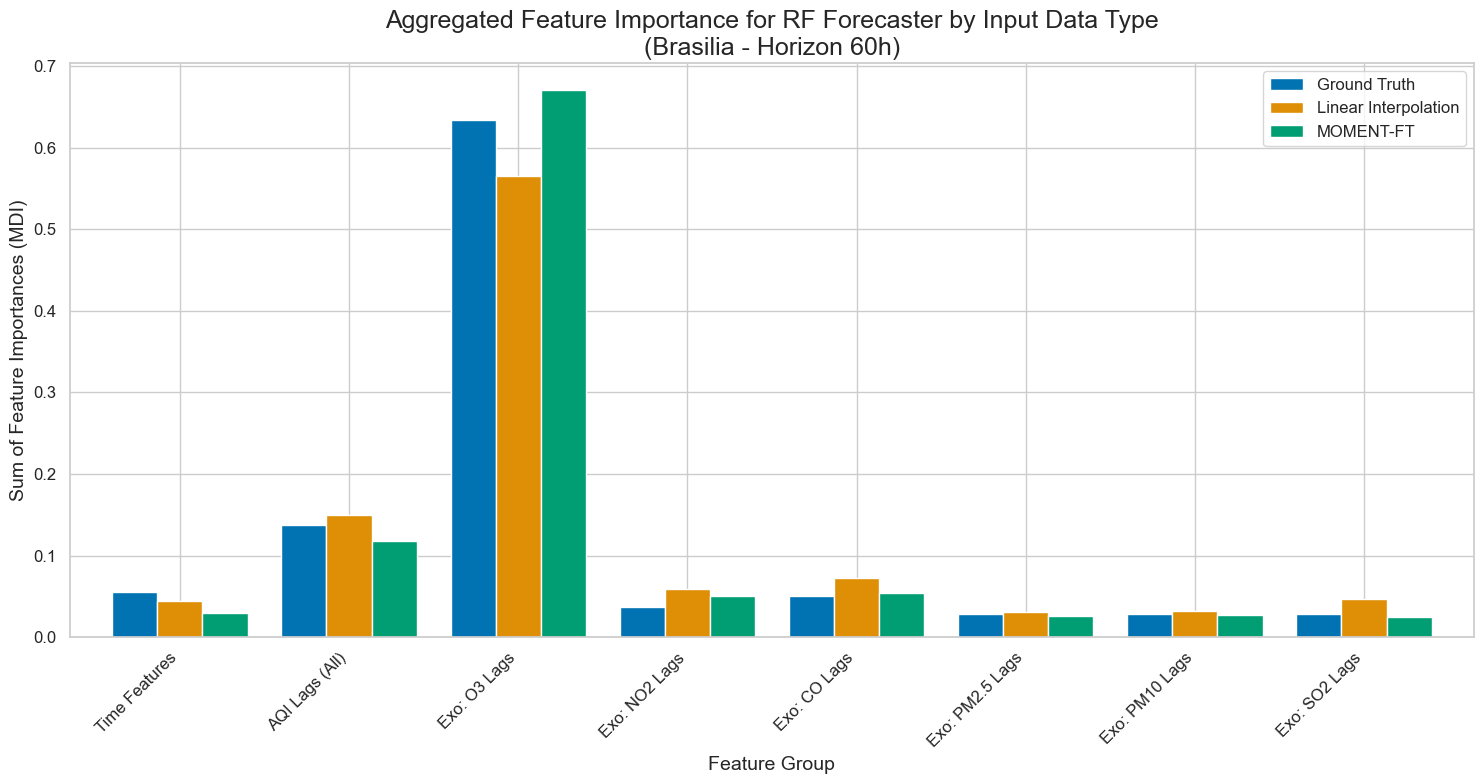


3-panel probabilistic comparative forecast plot saved to: c:\Users\fdemiguel\Documentos\TFM_Ambiental\AIR QUALITY\analisis_avanzado\probabilistic_forecast_comparison_3panel.png


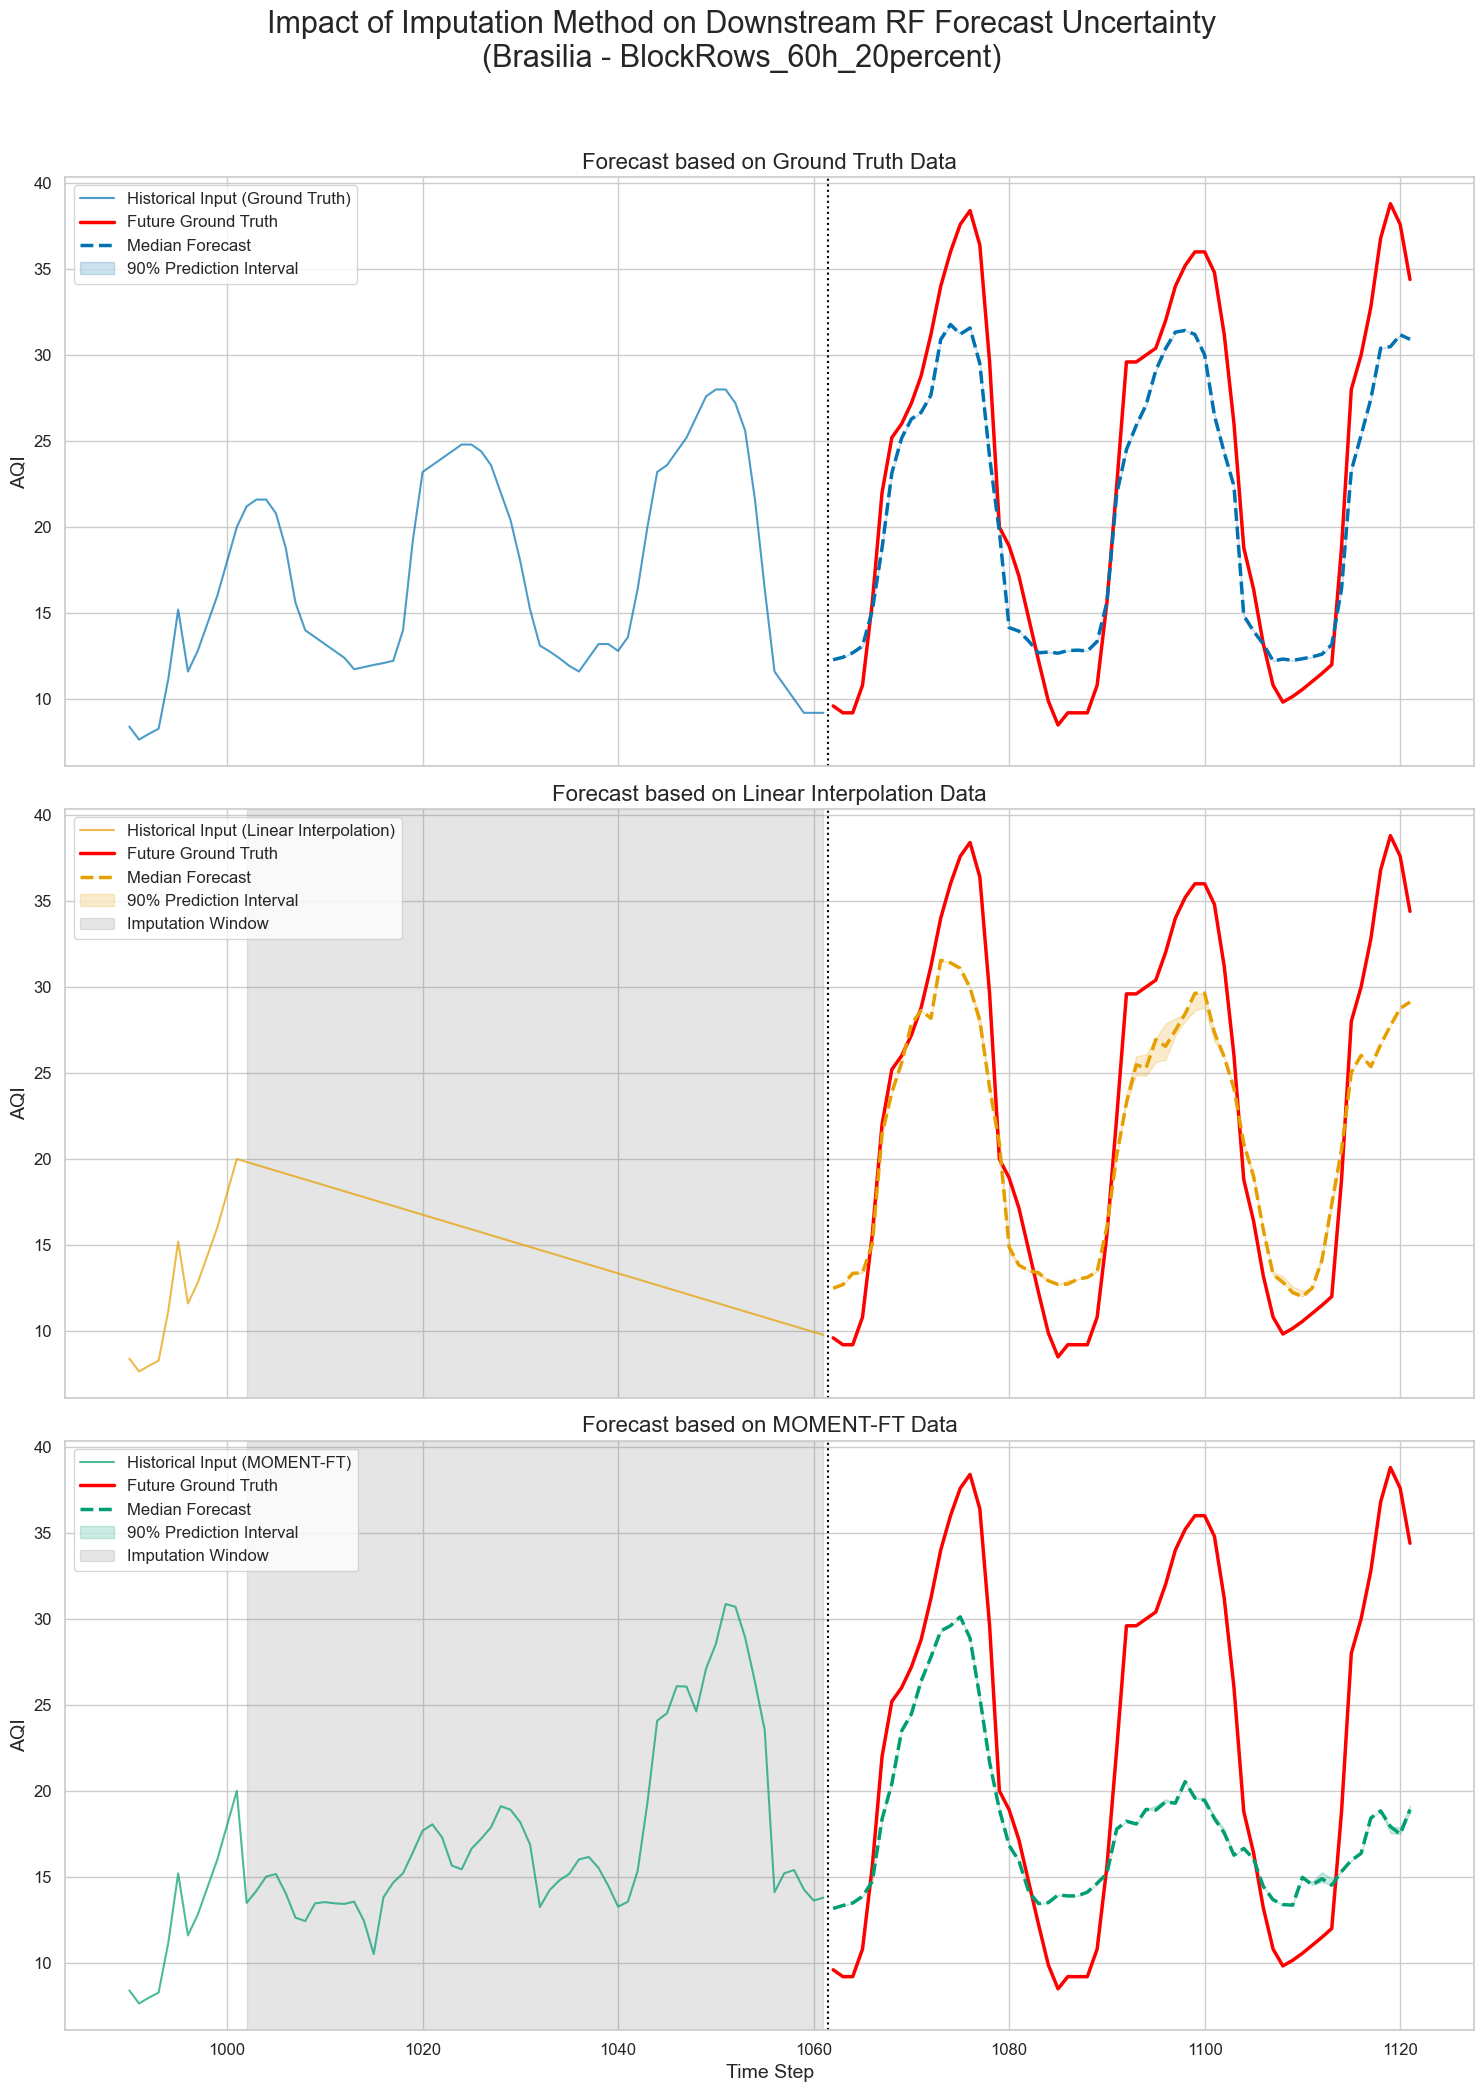

In [11]:
# =============================================================================
# CELDA 9: VISUALIZACIÓN UNIFICADA (FEATURE IMPORTANCE E INCERTIDUMBRE)
# =============================================================================
print("--- Generating Unified Comparative Plots (Feature Importance & Probabilistic Forecasts) ---")

# --- 1. Cargar datos necesarios ---
imputation_map_comp = {
    'Original (Ground Truth)': 'Ground Truth',
    'Linear Interpolation': 'Linear Interpolation',
    'MOMENT_FT_Optimized': 'MOMENT-FT'
}

imputed_dfs = {}
imputed_dfs['Ground Truth'] = df_gt_city.copy()

linear_path = find_imputed_file_robust('Linear Interpolation', CITY_FOR_ANALYSIS, SCENARIO_FOR_ANALYSIS, REP_FOR_ANALYSIS)
if linear_path:
    df_linear = pd.read_csv(linear_path)
    df_linear['Date'] = pd.to_datetime(df_linear['Date'])
    df_linear['Hour'], df_linear['DayOfWeek'], df_linear['Month'] = df_linear['Date'].dt.hour, df_linear['Date'].dt.dayofweek, df_linear['Date'].dt.month
    imputed_dfs['Linear Interpolation'] = df_linear
else:
    print("Warning: Could not find file for 'Linear Interpolation'")

moment_path = find_imputed_file_robust('MOMENT_FT_Optimized', CITY_FOR_ANALYSIS, SCENARIO_FOR_ANALYSIS, REP_FOR_ANALYSIS)
if moment_path:
    df_moment = pd.read_csv(moment_path)
    df_moment['Date'] = pd.to_datetime(df_moment['Date'])
    df_moment['Hour'], df_moment['DayOfWeek'], df_moment['Month'] = df_moment['Date'].dt.hour, df_moment['Date'].dt.dayofweek, df_moment['Date'].dt.month
    imputed_dfs['MOMENT-FT'] = df_moment
else:
    print("Warning: Could not find file for 'MOMENT-FT'")

nan_file_path = find_nan_file(CITY_FOR_ANALYSIS, SCENARIO_FOR_ANALYSIS, REP_FOR_ANALYSIS)
if not nan_file_path: raise FileNotFoundError("NaN file not found.")
df_with_nans = pd.read_csv(nan_file_path)
original_nan_indices = set(df_with_nans[df_with_nans[TARGET_VARIABLE].isnull()].index)

# --- 2. Definir parámetros UNIFICADOS y encontrar split_point ---
# *** USAMOS LA CONFIGURACIÓN CALIBRADA PARA TODO ***
N_LAGS_AQI_COMP = 72
N_LAGS_EXO_COMP = 72
HORIZON_COMP = 60
max_lags = max(N_LAGS_AQI_COMP, N_LAGS_EXO_COMP)

nan_blocks_series = df_with_nans[TARGET_VARIABLE].isnull().astype(int).diff().fillna(0)
starts = nan_blocks_series[nan_blocks_series == 1].index
ends = nan_blocks_series[nan_blocks_series == -1].index
if not starts.empty and (ends.empty or starts[0] > ends[0]):
    starts = starts.insert(0, df_with_nans[df_with_nans[TARGET_VARIABLE].isnull()].index[0])
if len(starts) > len(ends):
    ends = ends.append(pd.Index([df_with_nans[df_with_nans[TARGET_VARIABLE].isnull()].index[-1] + 1]))
nan_blocks = list(zip(starts, ends))

ideal_split_points = []
for start_nan, end_nan in nan_blocks:
    candidate_sp = end_nan
    history_start = candidate_sp - max_lags
    future_end = candidate_sp + HORIZON_COMP
    if history_start >= 0 and future_end <= len(df_gt_city):
        future_indices = set(range(candidate_sp, future_end))
        if not future_indices.intersection(original_nan_indices):
            ideal_split_points.append(candidate_sp)
if ideal_split_points:
    split_point = random.choice(ideal_split_points)
    print(f"Optimal split point (containing full NaN block) found at index: {split_point}")
else:
    print("Could not find a perfect split point containing a full NaN block. Using fallback logic.")
    possible_starts = range(max_lags + HORIZON_COMP, len(df_gt_city) - HORIZON_COMP)
    valid_split_points = [p for p in possible_starts if set(range(p - max_lags, p)).intersection(original_nan_indices) and not set(range(p, p + HORIZON_COMP)).intersection(original_nan_indices)]
    if not valid_split_points: raise ValueError("Could not find any suitable split point for visualization.")
    split_point = random.choice(valid_split_points)
    print(f"Fallback split point found at index: {split_point}")


# --- 3. Bucle para entrenar, generar predicciones y obtener importancias ---
plot_inputs = [('Ground Truth', '#0072B2'), ('Linear Interpolation', '#E69F00'), ('MOMENT-FT', '#009E73')]
all_feature_importances = {}
all_prob_predictions = {}

print(f"Training imputer ensemble for {CITY_FOR_ANALYSIS}...")
X_imp_train_full = create_univariant_features(df_gt_city, TARGET_VARIABLE, TIME_FEATURES, N_LAGS)
train_data_imp = pd.concat([X_imp_train_full, df_gt_city[TARGET_VARIABLE]], axis=1).dropna()
X_train_imp, y_train_imp = train_data_imp.drop(columns=[TARGET_VARIABLE]), train_data_imp[TARGET_VARIABLE]
imputer_ensemble = [RandomForestRegressor(n_estimators=50, n_jobs=-1, random_state=i, max_features=0.5, max_depth=10).fit(X_train_imp, y_train_imp) for i in range(N_IMPUTER_MODELS)]

df_with_nans_exog_filled = df_with_nans.copy()
for col in EXOGENOUS_COLS:
    if col in df_with_nans_exog_filled.columns:
        df_with_nans_exog_filled[col] = df_with_nans_exog_filled[col].interpolate(method='linear').ffill().bfill()
imputed_samples = generate_ensemble_rf_imputation_samples(df_with_nans_exog_filled, imputer_ensemble, N_MONTE_CARLO_SAMPLES)

for input_label, color in plot_inputs:
    print(f"Processing: {input_label}...")
    df_input = imputed_dfs.get(input_label)
    if df_input is None: continue

    # *** Entrenar SIEMPRE con la configuración calibrada (72 lags) ***
    X_train_full = create_multivariate_lagged_features_rf(df_input, TARGET_VARIABLE, EXOGENOUS_COLS, TIME_FEATURES, N_LAGS_AQI_COMP, N_LAGS_EXO_COMP, HORIZON_COMP)
    y_train_full = df_gt_city[TARGET_VARIABLE]
    train_data_comp = pd.concat([X_train_full, y_train_full], axis=1).dropna()
    X_train_c, y_train_c = train_data_comp.drop(columns=[TARGET_VARIABLE]), train_data_comp[TARGET_VARIABLE]
    
    rf_forecaster = RandomForestRegressor(n_estimators=30, random_state=42, n_jobs=-1, max_depth=10, min_samples_leaf=15, max_features=0.75)
    rf_forecaster.fit(X_train_c, y_train_c)
    
    all_feature_importances[input_label] = pd.Series(rf_forecaster.feature_importances_, index=X_train_c.columns)
    
    # Propagar incertidumbre usando la configuración calibrada
    prob_forecasts = propagate_uncertainty_to_forecasts_calibrated(imputed_samples, rf_forecaster, HORIZON_COMP)
    
    if input_label == 'Ground Truth' and not prob_forecasts.empty:
        # Para GT, la incertidumbre puede ser muy baja. Forzamos una predicción puntual para claridad.
        prediction = pd.Series(rf_forecaster.predict(X_train_full.loc[split_point : split_point + HORIZON_COMP - 1]), index=range(split_point, split_point + HORIZON_COMP))
        all_prob_predictions[input_label] = pd.concat([prediction] * N_MONTE_CARLO_SAMPLES, axis=1)
    elif not prob_forecasts.empty:
        all_prob_predictions[input_label] = prob_forecasts.loc[split_point : split_point + HORIZON_COMP - 1]

# --- 4. Crear el gráfico de Feature Importance ---
df_importances_all = pd.DataFrame(all_feature_importances)
def get_feature_group_simplified(feature_name):
    if feature_name in TIME_FEATURES: return 'Time Features'
    if 'AQI_lag' in feature_name: return 'AQI Lags (All)'
    for exo in EXOGENOUS_COLS:
        if f'{exo}_lag' in feature_name: return f'Exo: {exo} Lags'
    return 'Other'
df_importances_all['group'] = df_importances_all.index.map(get_feature_group_simplified)
df_summary = df_importances_all.groupby('group').sum()
category_order = ['Time Features', 'AQI Lags (All)', 'Exo: O3 Lags', 'Exo: NO2 Lags', 'Exo: CO Lags', 'Exo: PM2.5 Lags', 'Exo: PM10 Lags', 'Exo: SO2 Lags']
df_summary = df_summary.reindex(category_order).dropna()
df_summary.plot(kind='bar', figsize=(15, 8), width=0.8)
plt.title(f'Aggregated Feature Importance for RF Forecaster by Input Data Type\n(Brasilia - Horizon {HORIZON_COMP}h)')
plt.ylabel('Sum of Feature Importances (MDI)')
plt.xlabel('Feature Group')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
fi_plot_path = os.path.join(ANALYSIS_OUTPUT_DIR, 'feature_importance_comparison_simplified.png')
plt.savefig(fi_plot_path, dpi=300)
print(f"\nSimplified feature importance comparison plot saved to: {fi_plot_path}")
plt.show()

# --- 5. Crear el panel de 3 gráficos de predicción PROBABILÍSTICA ---
fig, axes = plt.subplots(3, 1, figsize=(15, 22), sharex=True, sharey=True)
fig.suptitle(f'Impact of Imputation Method on Downstream RF Forecast Uncertainty\n({CITY_FOR_ANALYSIS} - {SCENARIO_FOR_ANALYSIS})', fontsize=22)
for ax, (input_label, color) in zip(axes, plot_inputs):
    df_input = imputed_dfs.get(input_label)
    prob_forecasts = all_prob_predictions.get(input_label)
    if df_input is None or prob_forecasts is None or prob_forecasts.empty: continue
    
    median = prob_forecasts.median(axis=1)
    p05 = prob_forecasts.quantile(0.05, axis=1)
    p95 = prob_forecasts.quantile(0.95, axis=1)
    
    history_start = split_point - max_lags
    
    ax.plot(df_input.loc[history_start:split_point-1, TARGET_VARIABLE], label=f'Historical Input ({input_label})', color=color, alpha=0.7)
    ax.plot(df_gt_city.loc[split_point:split_point + HORIZON_COMP - 1, TARGET_VARIABLE], label='Future Ground Truth', color='red', linewidth=2.5, zorder=5)
    ax.plot(median, label='Median Forecast', color=color, linestyle='--', linewidth=2.5, zorder=6)
    ax.fill_between(median.index, p05, p95, color=color, alpha=0.2, label='90% Prediction Interval')
    
    history_nan_indices = [i for i in original_nan_indices if history_start <= i < split_point]
    if history_nan_indices and input_label != 'Ground Truth':
        block_starts_in_window = [s for s, e in nan_blocks if history_start <= s < split_point]
        block_ends_in_window = [e for s, e in nan_blocks if history_start < e <= split_point]
        if block_starts_in_window and block_ends_in_window:
             ax.axvspan(min(block_starts_in_window), max(block_ends_in_window)-1, color='gray', alpha=0.2, label='Imputation Window')

    ax.axvline(x=split_point - 0.5, color='black', linestyle=':', linewidth=1.5)
    ax.set_title(f'Forecast based on {input_label} Data', fontsize=16)
    ax.set_ylabel(TARGET_VARIABLE)
    ax.legend(loc='upper left')
    ax.grid(True)

axes[-1].set_xlabel('Time Step')
plt.tight_layout(rect=[0, 0.03, 1, 0.96])
comp_plot_path_3panel_prob = os.path.join(ANALYSIS_OUTPUT_DIR, 'probabilistic_forecast_comparison_3panel.png')
plt.savefig(comp_plot_path_3panel_prob, dpi=300)
print(f"\n3-panel probabilistic comparative forecast plot saved to: {comp_plot_path_3panel_prob}")
plt.show()

In [15]:
# =============================================================================
# CELDA 10: CÁLCULO SISTEMÁTICO MULTI-CIUDAD DE MÉTRICAS DE INCERTIDUMBRE + PLOTS (VERSIÓN FINAL)
# =============================================================================
print("--- Generating Final Probabilistic Metrics & Plots for ALL CITIES ---")

# Lista de todos los escenarios que procesaste
all_scenarios = [
    'BlockRows_12h_20percent', 'BlockRows_24h_20percent', 
    'BlockRows_36h_20percent', 'BlockRows_48h_20percent', 
    'BlockRows_60h_20percent', 'RandomRows_20percent'
]
# Métodos para los que podemos generar incertidumbre.
probabilistic_methods_map = {
    'Linear Interpolation': 'Linear Interpolation',
    'LSTM-VAE': 'LSTM-VAE',
    'MOMENT Pretrained': 'MOMENT Pretrained',
    'MOMENT_FT_Optimized': 'MOMENT-FT',
    'Random Forest': 'Random Forest',
    'SARIMA': 'SARIMA'
}
# Almacenar todos los resultados
uq_results = []
cities_to_process = df_ground_truth_raw['City'].unique()

# Bucle principal sobre ciudades
for city in cities_to_process:
    print(f"\n{'='*20} PROCESSING CITY: {city.upper()} {'='*20}")
    
    df_city_gt = df_ground_truth_raw[df_ground_truth_raw['City'] == city].reset_index(drop=True)
    if df_city_gt.empty: continue
    df_city_gt['Date'] = pd.to_datetime(df_city_gt['Date'], utc=True) # Convertir a UTC
    df_city_gt['Hour'], df_city_gt['DayOfWeek'], df_city_gt['Month'] = df_city_gt['Date'].dt.hour, df_city_gt['Date'].dt.dayofweek, df_city_gt['Date'].dt.month
    df_city_gt[TARGET_VARIABLE] = df_city_gt[TARGET_VARIABLE].ffill().bfill()
    if df_city_gt.isnull().values.any(): continue

    print(f"  Training imputer ensemble for {city}...")
    X_imp_train_full = create_univariant_features(df_city_gt, TARGET_VARIABLE, TIME_FEATURES, N_LAGS)
    train_data_imp = pd.concat([X_imp_train_full, df_city_gt[TARGET_VARIABLE]], axis=1).dropna()
    X_train_imp, y_train_imp = train_data_imp.drop(columns=[TARGET_VARIABLE]), train_data_imp[TARGET_VARIABLE]
    if X_train_imp.empty: continue
    imputer_ensemble = [RandomForestRegressor(n_estimators=50, n_jobs=-1, random_state=i, max_features=0.5, max_depth=10).fit(X_train_imp, y_train_imp) for i in range(N_IMPUTER_MODELS)]

    for scenario in tqdm(all_scenarios, desc=f"Scenarios in {city}"):
        nan_file = find_nan_file(city, scenario, REP_FOR_ANALYSIS)
        if not nan_file: continue
        df_with_nans = pd.read_csv(nan_file)
        # --- *** CORRECCIÓN DE ZONA HORARIA 1 *** ---
        df_with_nans['Date'] = pd.to_datetime(df_with_nans['Date'], utc=True)
        
        for col in EXOGENOUS_COLS:
            if col in df_with_nans.columns:
                df_with_nans[col] = df_with_nans[col].interpolate(method='linear').ffill().bfill()
        
        imputed_samples = generate_ensemble_rf_imputation_samples(df_with_nans, imputer_ensemble, N_MONTE_CARLO_SAMPLES)
        
        for method_folder, method_label in probabilistic_methods_map.items():
            imputed_file_path = find_imputed_file_robust(method_folder, city, scenario, REP_FOR_ANALYSIS)
            if not imputed_file_path: continue
            df_input = pd.read_csv(imputed_file_path)
            # --- *** CORRECCIÓN DE ZONA HORARIA 2 *** ---
            df_input['Date'] = pd.to_datetime(df_input['Date'], utc=True)
            df_input['Hour'], df_input['DayOfWeek'], df_input['Month'] = df_input['Date'].dt.hour, df_input['Date'].dt.dayofweek, df_input['Date'].dt.month
            
            X_train_full = create_multivariate_lagged_features_rf(df_input, TARGET_VARIABLE, EXOGENOUS_COLS, TIME_FEATURES, N_LAGS_AQI_CALIBRATED, N_LAGS_EXO_CALIBRATED, HORIZON_COMP)
            y_train_full = df_city_gt[TARGET_VARIABLE]
            train_data = pd.concat([X_train_full, y_train_full], axis=1).dropna()
            X_train_c, y_train_c = train_data.drop(columns=[TARGET_VARIABLE]), train_data[TARGET_VARIABLE]
            if X_train_c.empty: continue
            
            rf_forecaster = RandomForestRegressor(n_estimators=30, random_state=42, n_jobs=-1, max_depth=10, min_samples_leaf=15, max_features=0.75)
            rf_forecaster.fit(X_train_c, y_train_c)
            
            prob_forecasts = propagate_uncertainty_to_forecasts_calibrated(imputed_samples, rf_forecaster, HORIZON_COMP)
            
            if not prob_forecasts.empty:
                y_true_eval = df_city_gt.loc[prob_forecasts.index, TARGET_VARIABLE].values
                samples_eval = prob_forecasts.values
                p05, p95 = prob_forecasts.quantile(0.05, axis=1).values, prob_forecasts.quantile(0.95, axis=1).values
                w_score, c_score = winkler_score(y_true_eval, p05, p95, alpha=0.1), crps(y_true_eval, samples_eval)
                uq_results.append({'City': city, 'Scenario': scenario, 'Imputation_Method': method_label, 'Winkler_Score': w_score, 'CRPS': c_score})

                if city == cities_to_process[0]:
                    plot_start_index = prob_forecasts.index[len(prob_forecasts) // 2]
                    plot_end_index = plot_start_index + HORIZON_COMP
                    forecast_slice = prob_forecasts.loc[plot_start_index:plot_end_index-1]
                    if not forecast_slice.empty:
                        median, p05_plot, p95_plot = forecast_slice.median(axis=1), forecast_slice.quantile(0.05, axis=1), forecast_slice.quantile(0.95, axis=1)
                        plt.figure(figsize=(16, 8))
                        history_start = plot_start_index - max_lags
                        plt.plot(df_city_gt.loc[history_start:plot_start_index-1, TARGET_VARIABLE], label='Historical Ground Truth', color='black')
                        plt.plot(df_city_gt.loc[plot_start_index:plot_end_index-1, TARGET_VARIABLE], label='Future Ground Truth', color='red', linewidth=2.5, zorder=3)
                        plt.plot(median, label=f'Median Forecast ({method_label})', color='blue', linestyle='--', zorder=4)
                        plt.fill_between(median.index, p05_plot, p95_plot, color='blue', alpha=0.2, label='90% Prediction Interval', zorder=2)
                        plt.title(f'Probabilistic Forecast in {city}\nScenario: {scenario} | Imputation: {method_label}')
                        plt.xlabel('Time Step'); plt.ylabel(TARGET_VARIABLE); plt.legend(); plt.grid(True)
                        
                        plot_dir = os.path.join(ANALYSIS_OUTPUT_DIR, 'scenario_examples', city.replace(" ", "_"))
                        os.makedirs(plot_dir, exist_ok=True)
                        plot_path = os.path.join(plot_dir, f'uq_example_{scenario}_{method_label.replace(" ", "")}.png')
                        plt.savefig(plot_path, dpi=200)
                        plt.close()

# --- Crear y mostrar la tabla de resultados finales (sin cambios) ---
if uq_results:
    df_uq_results = pd.DataFrame(uq_results)
    df_uq_summary = df_uq_results.groupby('Imputation_Method')[['Winkler_Score', 'CRPS']].mean().sort_values('CRPS')
    
    print("\n\n--- Summary of Probabilistic Forecasting Performance (Averaged Across All Cities & Scenarios) ---")
    print(df_uq_summary)
    
    summary_path = os.path.join(ANALYSIS_OUTPUT_DIR, 'probabilistic_metrics_summary_all_cities.csv')
    df_uq_summary.to_csv(summary_path)
    print(f"\nSummary table saved to: {summary_path}")
    
    df_uq_summary_by_city = df_uq_results.groupby(['City', 'Imputation_Method'])[['Winkler_Score', 'CRPS']].mean().sort_values(['City', 'CRPS'])
    print("\n--- Detailed Summary by City ---")
    print(df_uq_summary_by_city.to_string())
    summary_city_path = os.path.join(ANALYSIS_OUTPUT_DIR, 'probabilistic_metrics_by_city.csv')
    df_uq_summary_by_city.to_csv(summary_city_path)
    print(f"\nDetailed summary by city saved to: {summary_city_path}")

--- Generating Final Probabilistic Metrics & Plots for ALL CITIES ---

==================== PROCESSING CITY: BRASILIA ====================
  Training imputer ensemble for Brasilia...


Scenarios in Brasilia:   0%|          | 0/6 [00:00<?, ?it/s]

DEBUG: Varianza de las predicciones de los modelos para el primer NaN: 0.00913617440626122


Generando muestras de imputación RF (Ensamblaje):   0%|          | 0/50 [00:00<?, ?it/s]

Propagando incertidumbre (calibrated model):   0%|          | 0/50 [00:00<?, ?it/s]

...

Propagando incertidumbre (calibrated model):   0%|          | 0/50 [00:00<?, ?it/s]

Propagando incertidumbre (calibrated model):   0%|          | 0/50 [00:00<?, ?it/s]

Propagando incertidumbre (calibrated model):   0%|          | 0/50 [00:00<?, ?it/s]

Propagando incertidumbre (calibrated model):   0%|          | 0/50 [00:00<?, ?it/s]



--- Summary of Probabilistic Forecasting Performance (Averaged Across All Cities & Scenarios) ---
                      Winkler_Score      CRPS
Imputation_Method                            
Linear Interpolation      82.355070  4.129315
Random Forest             91.635098  4.593089
LSTM-VAE                  99.624539  4.991546
MOMENT Pretrained        101.087436  5.066537
SARIMA                   101.242730  5.073716
MOMENT-FT                101.443602  5.083668

Summary table saved to: c:\Users\fdemiguel\Documentos\TFM_Ambiental\AIR QUALITY\analisis_avanzado\probabilistic_metrics_summary_all_cities.csv

--- Detailed Summary by City ---
                               Winkler_Score      CRPS
City     Imputation_Method                            
Brasilia Linear Interpolation      50.740248  2.549712
         MOMENT Pretrained         64.721590  3.253380
         LSTM-VAE                  65.114286  3.266545
         Random Forest             65.320617  3.279536
         SARIMA         

--- Generating Final Summary Plots with Legend and Dynamic Y-axis ---

Global performance plot (vertical) saved to: c:\Users\fdemiguel\Documentos\TFM_Ambiental\AIR QUALITY\analisis_avanzado\global_probabilistic_performance_vertical.png


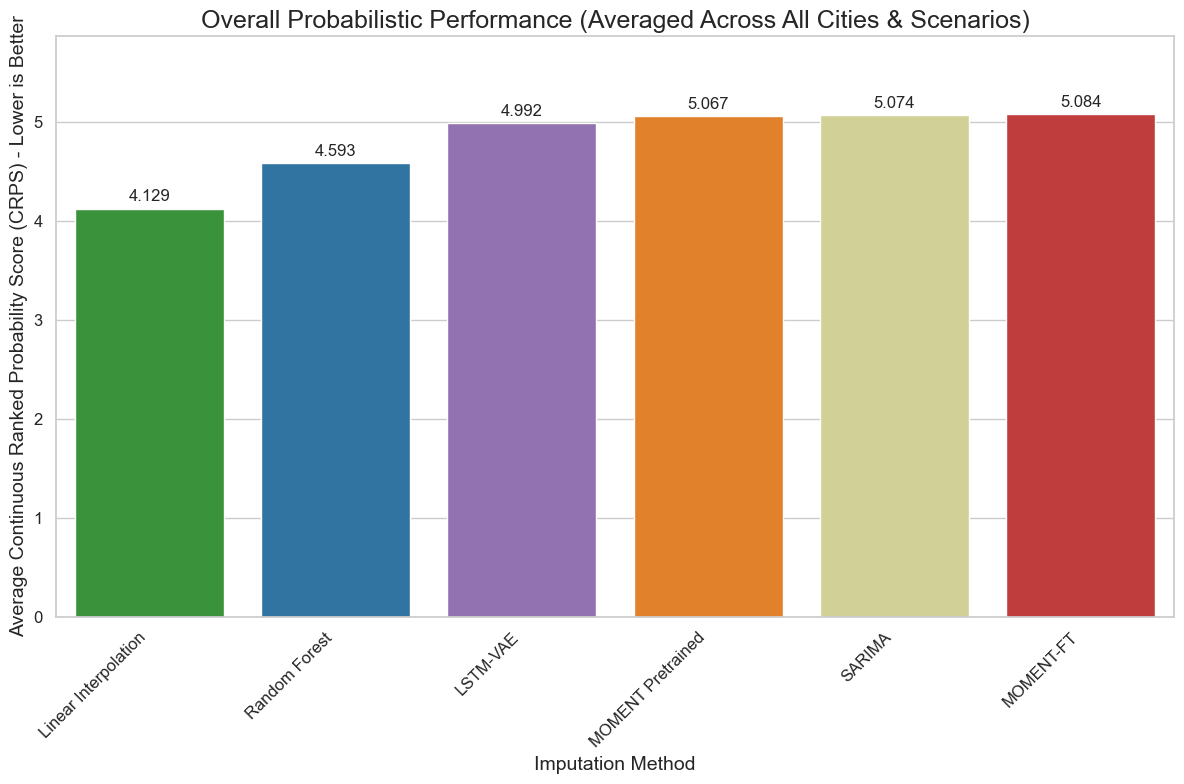

City-specific performance plot (with legend) saved to: c:\Users\fdemiguel\Documentos\TFM_Ambiental\AIR QUALITY\analisis_avanzado\city_probabilistic_performance_with_legend.png


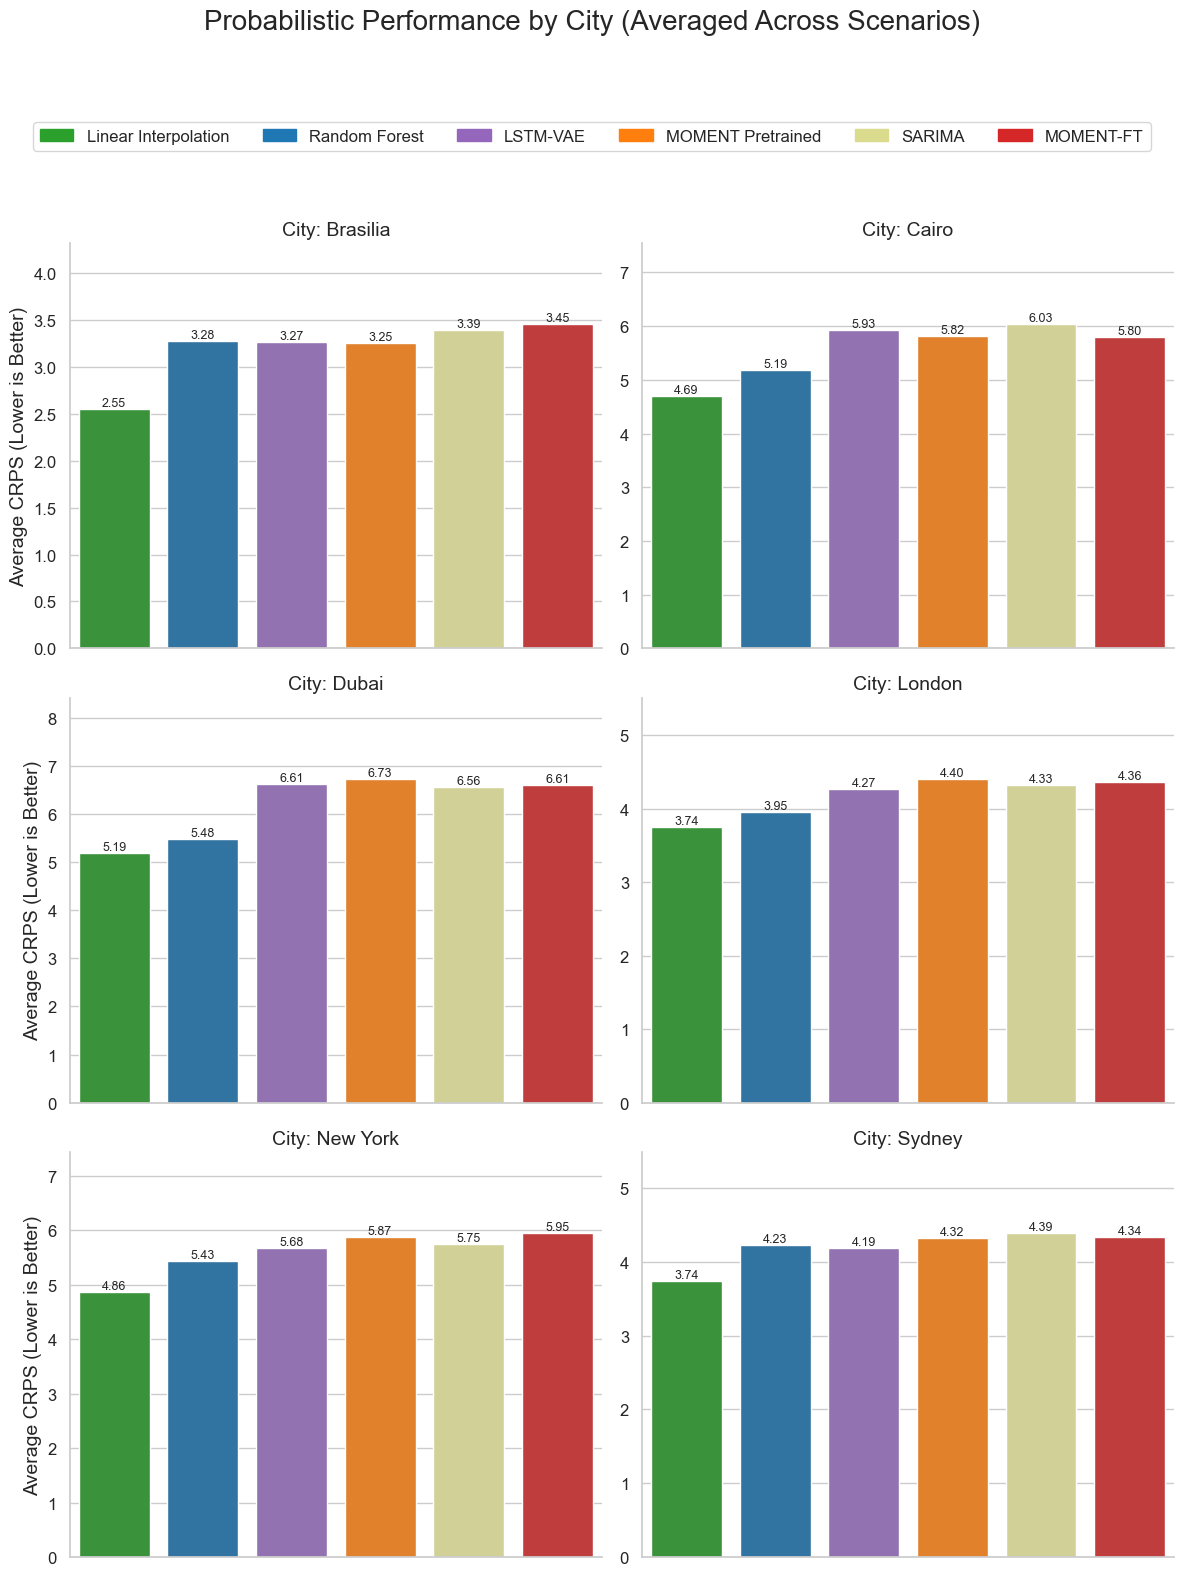

In [30]:
# =============================================================================
# CELDA 11: VISUALIZACIÓN FINAL (CON LEYENDA Y EJE Y DINÁMICO)
# =============================================================================
print("--- Generating Final Summary Plots with Legend and Dynamic Y-axis ---")

# Usamos los DataFrames que generamos en la celda anterior
if 'df_uq_summary' in locals() and 'df_uq_summary_by_city' in locals():
    
    # --- Paleta de colores personalizada (sin cambios) ---
    custom_palette = ['#2ca02c', '#1f77b4', '#9467bd', '#ff7f0e', '#dbdb8d', '#d62728']

    # --- GRÁFICO 1: RENDIMIENTO GLOBAL (BARRAS VERTICALES) ---
    plt.figure(figsize=(12, 8))
    
    df_global_sorted = df_uq_summary.sort_values('CRPS', ascending=True)
    num_methods = len(df_global_sorted.index)
    
    ax1 = sns.barplot(
        x=df_global_sorted.index,
        y='CRPS',
        data=df_global_sorted,
        palette=custom_palette[:num_methods]
    )
    
    ax1.set_title('Overall Probabilistic Performance (Averaged Across All Cities & Scenarios)', fontsize=18)
    ax1.set_ylabel('Average Continuous Ranked Probability Score (CRPS) - Lower is Better', fontsize=14)
    ax1.set_xlabel('Imputation Method', fontsize=14)
    plt.xticks(rotation=45, ha='right')
    
    for container in ax1.containers:
        ax1.bar_label(container, fmt='%.3f', padding=3)
    
    ax1.set_ylim(top=ax1.get_ylim()[1] * 1.1)
    plt.tight_layout()
    global_plot_path = os.path.join(ANALYSIS_OUTPUT_DIR, 'global_probabilistic_performance_vertical.png')
    plt.savefig(global_plot_path, dpi=300)
    print(f"\nGlobal performance plot (vertical) saved to: {global_plot_path}")
    plt.show()

    
    # --- GRÁFICO 2: RENDIMIENTO DETALLADO POR CIUDAD (CON LEYENDA) ---
    
    plot_order = df_global_sorted.index.tolist()
    color_map = {method: color for method, color in zip(plot_order, custom_palette)}

    g = sns.catplot(
        x='Imputation_Method',
        y='CRPS',
        col='City',
        data=df_uq_summary_by_city.reset_index(),
        kind='bar',
        height=5, 
        aspect=1.2, 
        col_wrap=2,
        palette=color_map,
        order=plot_order,
        sharey=False 
    )
    
    g.fig.suptitle('Probabilistic Performance by City (Averaged Across Scenarios)', y=1.05, fontsize=20) # Aumentamos y para dejar espacio
    g.set_axis_labels('', 'Average CRPS (Lower is Better)') # Quitamos el label del eje X
    g.set_titles("City: {col_name}")
    g.set_xticklabels([]) # Ocultamos las etiquetas de texto del eje X
    
    for ax in g.axes.flatten():
        max_val = 0
        for container in ax.containers:
            labels = [f'{v.get_height():.2f}' for v in container]
            ax.bar_label(container, labels=labels, fontsize=9)
            
            current_max = max([v.get_height() for v in container if v.get_height() is not np.nan] or [0])
            if current_max > max_val:
                max_val = current_max

        if max_val > 0:
            ax.set_ylim(top=max_val * 1.25)
    
    # --- *** LÓGICA PARA AÑADIR LA LEYENDA GLOBAL *** ---
    import matplotlib.patches as mpatches
    
    # Crear los "patches" (rectángulos de color) para la leyenda
    legend_patches = [mpatches.Patch(color=color, label=label) for label, color in color_map.items()]
    
    # Añadir la leyenda a la figura, posicionándola debajo del título
    g.fig.legend(handles=legend_patches, loc='upper center', bbox_to_anchor=(0.5, 0.98), ncol=len(plot_order))
    # --- *** FIN DEL CÓDIGO DE LEYENDA *** ---
    
    plt.tight_layout(rect=[0, 0, 1, 0.95]) # Ajustar para que no se corte la leyenda
    city_plot_path = os.path.join(ANALYSIS_OUTPUT_DIR, 'city_probabilistic_performance_with_legend.png')
    g.savefig(city_plot_path, dpi=300)
    print(f"City-specific performance plot (with legend) saved to: {city_plot_path}")
    plt.show()

else:
    print("DataFrames 'df_uq_summary' or 'df_uq_summary_by_city' not found. Please run the previous cell.")